# Librerias

In [1]:
import sys
import os
import datetime
import shutil

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('../')))


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import folium
from folium.plugins import HeatMap
from geopy.geocoders import Nominatim



In [3]:

from src.Tabular_Data_Processor import TabularDataProcessor


# Instancias para analisis

In [4]:
vectoria_acciones = TabularDataProcessor(
    ).load_data('../data/raw/vectoria_acciones.csv',
                sep = ',', decimal = '.', header = 0)

vectoria_casos_cantonal_anual_real = TabularDataProcessor(
    ).load_data('../data/raw/vectoria_casos_cantonal_anual_real.csv',
                sep = ',', decimal = '.', header = 0)

vectoria_dengue_nacional_real = TabularDataProcessor(
    ).load_data('../data/raw/vectoria_dengue_nacional_real.csv',
                sep = ',', decimal = '.', header = 0)

vectoria_dengue_semanal = TabularDataProcessor(
    ).load_data('../data/raw/vectoria_dengue_semanal.csv',
                sep = ',', decimal = '.', header = 0)



## Analisis de vectoria_acciones

In [5]:
vectoria_acciones.data['fecha_inicio_semana'] = pd.to_datetime(vectoria_acciones.data['fecha_inicio_semana'])
vectoria_acciones.data = vectoria_acciones.data.set_index('fecha_inicio_semana')



vectoria_acciones.data.shape

(2060, 11)

In [6]:

vectoria_acciones.data.head(20)

,anio,semana_epi,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
fecha_inicio_semana,,,,,,,,,,,
2017-01-01,2017,1,1,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
2017-01-01,2017,1,2,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2017-01-01,2017,1,3,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2017-01-01,2017,1,4,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2017-01-01,2017,1,5,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2017-01-08,2017,2,1,302,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
2017-01-08,2017,2,2,331,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
2017-01-08,2017,2,3,315,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
2017-01-08,2017,2,4,339,1720,59.2,26.3,20.2,84.4,1,monitoreo_normal


In [7]:
vectoria_acciones.data.drop(columns = ['aegypti_detectado', 'recomendacion', 'anio', 'semana_epi', 'escenario']).describe()

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad
count,2060.000000,2060.000000,2060.000000,2060.000000,2060.000000,2060.000000
mean,1006.491262,999.669903,113.226699,27.766505,21.105583,84.141748
std,1334.228294,603.585227,106.761499,1.662033,0.925644,7.367858
min,75.000000,210.000000,0.300000,24.400000,18.400000,64.300000
25%,244.000000,464.750000,32.125000,26.600000,20.500000,80.225000
50%,490.000000,871.000000,95.200000,27.300000,21.200000,87.000000
75%,1086.000000,1411.000000,163.350000,28.700000,21.800000,89.500000
max,10021.000000,2612.000000,867.600000,32.700000,23.200000,94.900000


In [8]:
vectoria_acciones.data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2060 entries, 2017-01-01 to 2024-11-24
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   anio                   2060 non-null   int64  
 1   semana_epi             2060 non-null   int64  
 2   escenario              2060 non-null   int64  
 3   casos_pred_4sem        2060 non-null   int64  
 4   casos_umbral_endemico  2060 non-null   int64  
 5   lluvia_14d_mm          2060 non-null   float64
 6   temp_max               2060 non-null   float64
 7   temp_min               2060 non-null   float64
 8   humedad                2060 non-null   float64
 9   aegypti_detectado      2060 non-null   int64  
 10  recomendacion          2060 non-null   str    
dtypes: float64(4), int64(6), str(1)
memory usage: 227.6 KB


In [9]:
vectoria_acciones.data.nunique()

anio                        8
semana_epi                 52
escenario                   5
casos_pred_4sem          1163
casos_umbral_endemico     287
lluvia_14d_mm             372
temp_max                   77
temp_min                   48
humedad                   192
aegypti_detectado           2
recomendacion               4
dtype: int64

In [10]:
vectoria_acciones.data.drop(columns = ['anio', 'semana_epi'], inplace = True)

/tmp/ipykernel_134566/142797716.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  vectoria_acciones.data.drop(columns = ['anio', 'semana_epi'], inplace = True)


<Axes: xlabel='fecha_inicio_semana'>

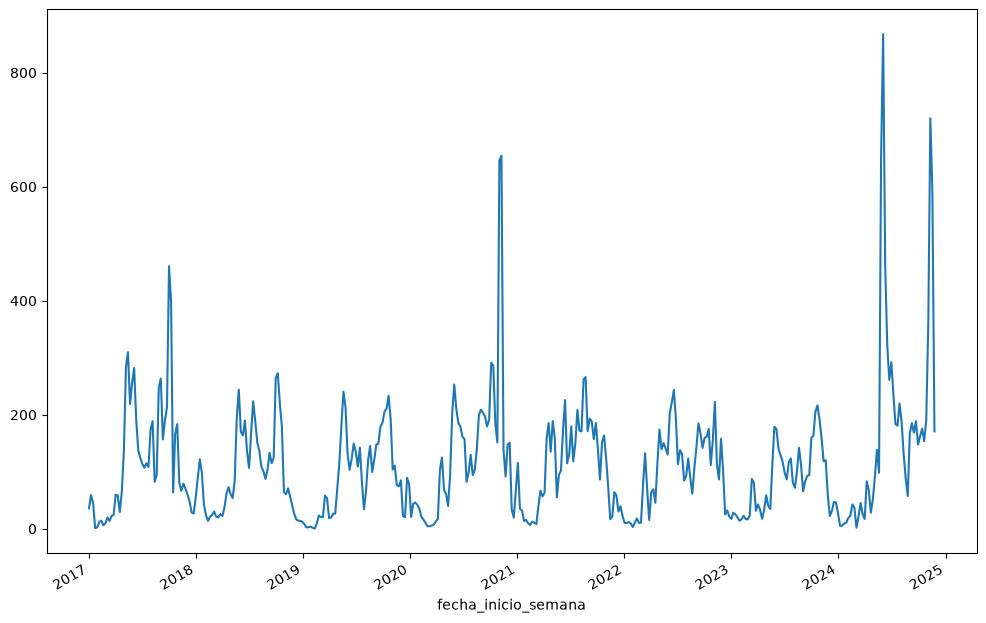

In [11]:
vectoria_acciones.data['lluvia_14d_mm'].plot(figsize=(12,8))

<Axes: xlabel='fecha_inicio_semana'>

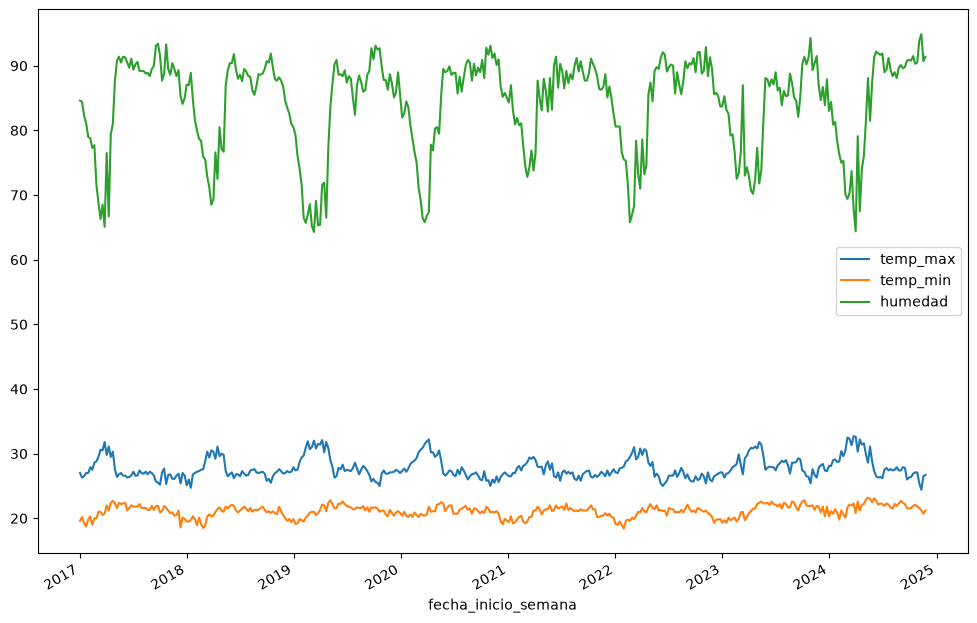

In [12]:
vectoria_acciones.data.drop(columns = ['casos_pred_4sem', 'casos_umbral_endemico', 'aegypti_detectado', 'recomendacion', 'lluvia_14d_mm', 'escenario']).plot(figsize=(12,8))

<Axes: xlabel='fecha_inicio_semana'>

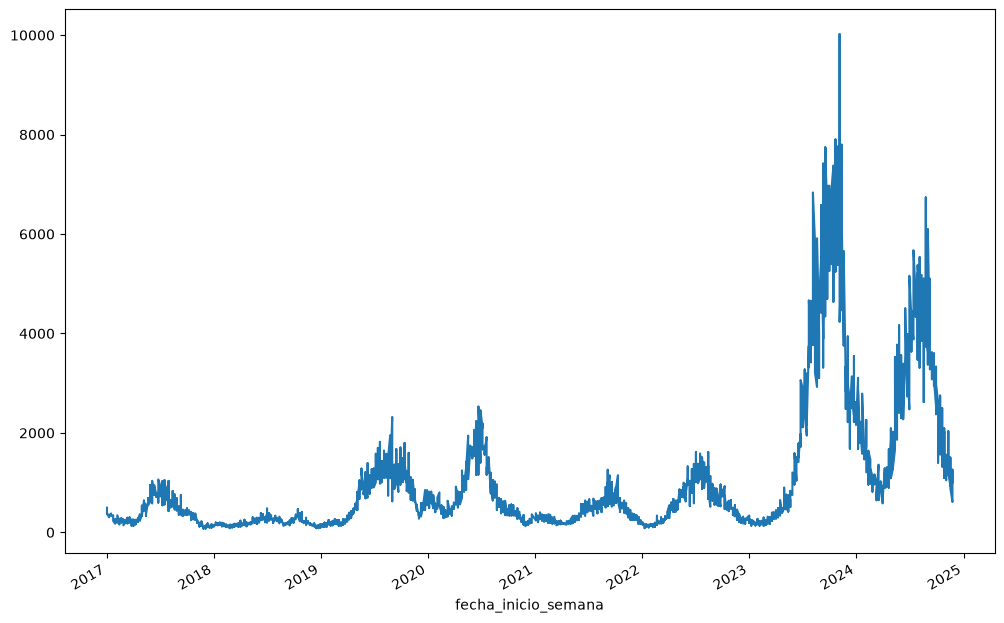

In [13]:
vectoria_acciones.data['casos_pred_4sem'].plot(figsize=(12,8))

<Axes: xlabel='fecha_inicio_semana'>

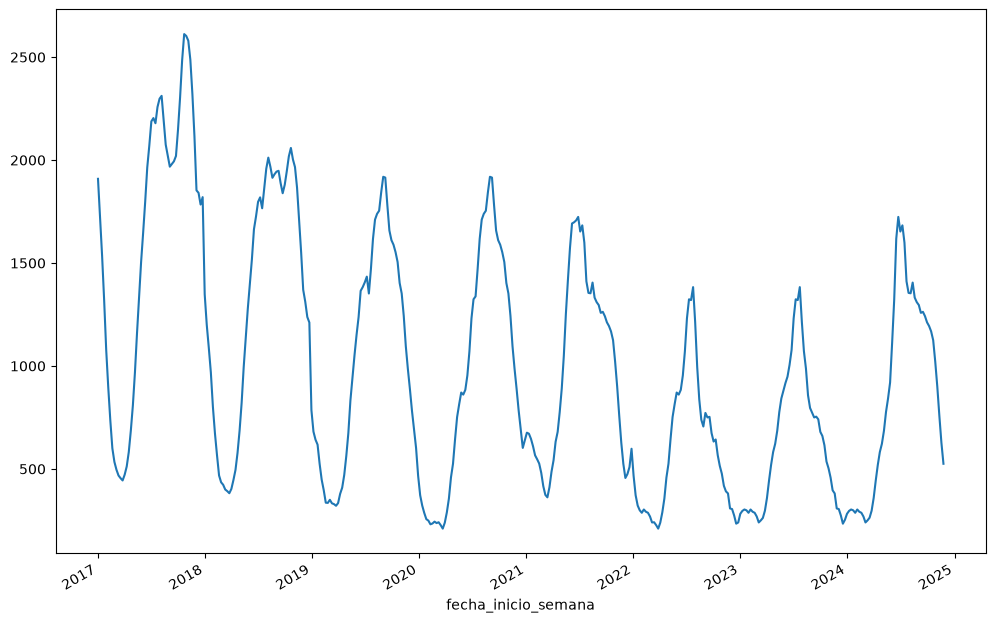

In [14]:
vectoria_acciones.data['casos_umbral_endemico'].plot(figsize=(12,8))

In [15]:
vectoria_acciones.data['recomendacion'].unique()

<ArrowStringArray>
[     'monitoreo_normal', 'eliminacion_criaderos', 'fumigacion_focalizada',
      'alerta_sanitaria']
Length: 4, dtype: str

In [16]:
vectoria_acciones.set_categorical_columns(
        columna = 'recomendacion',
        categorias = ['monitoreo_normal', 'eliminacion_criaderos', 'fumigacion_focalizada', 'alerta_sanitaria'], 
        ordered=True
    )

La data en general presenta estacionalidad con picos altos en fechas de aproximadamete mitad de año y picos bajos a principios/finales de año tipico del clima tropical del terriotorio costarricense, dandose cada pico segun se va combiando entre la estacion seca(diciembre a abril) y la estacion lluviosa(mayo a noviembre).

Se detectan picos en los casos de denge segun el README.md de la data proprcionada, dandose los picos altos en las temporadas de lluvia.

### Vista de datos por escenario

#### Escenario 1

In [17]:
escenario_1 = vectoria_acciones.data[vectoria_acciones.data['escenario'] == 1].drop(columns =['escenario'])
escenario_1

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
fecha_inicio_semana,,,,,,,,
2017-01-01,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
2017-01-08,302,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
2017-01-15,374,1535,45.4,26.5,19.2,82.3,0,monitoreo_normal
2017-01-22,345,1319,1.1,27.0,18.7,81.1,0,monitoreo_normal
2017-01-29,173,1078,2.5,27.0,19.8,79.0,0,monitoreo_normal
...,...,...,...,...,...,...,...,...
2024-10-27,2023,1021,190.4,27.1,21.8,90.5,1,fumigacion_focalizada
2024-11-03,1047,900,360.6,25.4,21.6,93.9,1,fumigacion_focalizada
2024-11-10,1146,759,719.8,24.4,21.2,94.9,0,monitoreo_normal


In [18]:
escenario_1.drop(columns = ['aegypti_detectado', 'recomendacion']).describe()

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad
count,412.000000,412.000000,412.000000,412.000000,412.000000,412.000000
mean,1004.381068,999.669903,113.226699,27.766505,21.105583,84.141748
std,1348.847244,604.172373,106.865353,1.663650,0.926544,7.375026
min,81.000000,210.000000,0.300000,24.400000,18.400000,64.300000
25%,242.250000,464.750000,32.125000,26.600000,20.500000,80.225000
50%,480.000000,871.000000,95.200000,27.300000,21.200000,87.000000
75%,1077.750000,1411.000000,163.350000,28.700000,21.800000,89.500000
max,7909.000000,2612.000000,867.600000,32.700000,23.200000,94.900000


('monitoreo_normal', 'eliminacion_criaderos', 'fumigacion_focalizada', 'alerta_sanitaria')


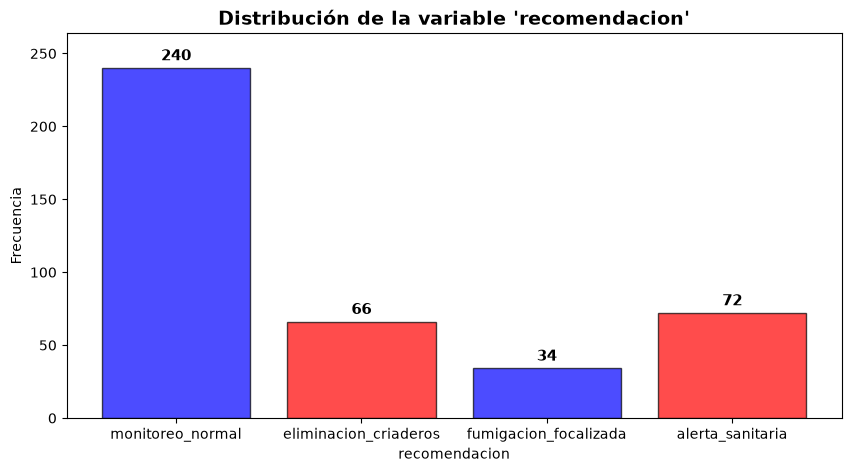

In [19]:
vectoria_acciones.graficos.plot_bar(escenario_1, 'recomendacion')

In [20]:
cantidades = escenario_1['recomendacion'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_1['recomendacion'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

58.25% de datos avarcados por la categoria monitoreo_normal
17.48% de datos avarcados por la categoria alerta_sanitaria
16.02% de datos avarcados por la categoria eliminacion_criaderos
8.25% de datos avarcados por la categoria fumigacion_focalizada


('1', '0')


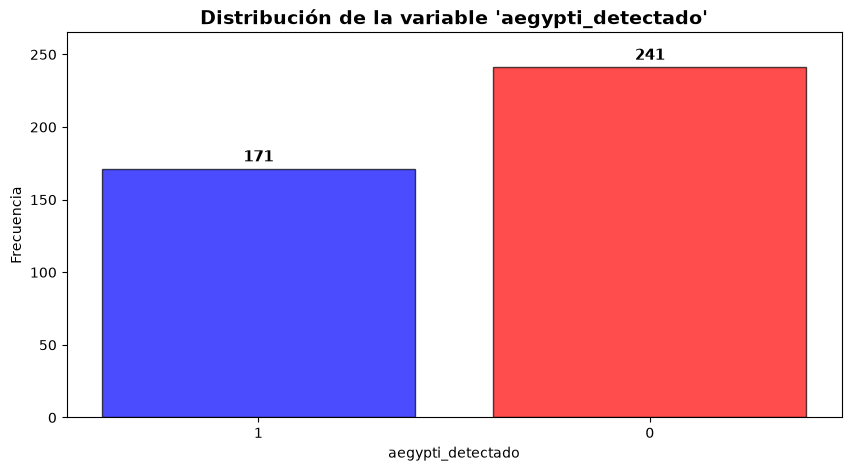

In [21]:
vectoria_acciones.graficos.plot_bar(escenario_1, 'aegypti_detectado')

In [22]:
cantidades = escenario_1['aegypti_detectado'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_1['aegypti_detectado'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

58.50% de datos avarcados por la categoria 0
41.50% de datos avarcados por la categoria 1


#### Escenario 2

In [23]:
escenario_2 = vectoria_acciones.data[vectoria_acciones.data['escenario'] == 2].drop(columns =['escenario'])
escenario_2

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
fecha_inicio_semana,,,,,,,,
2017-01-01,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2017-01-08,331,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
2017-01-15,339,1535,45.4,26.5,19.2,82.3,1,monitoreo_normal
2017-01-22,259,1319,1.1,27.0,18.7,81.1,0,monitoreo_normal
2017-01-29,226,1078,2.5,27.0,19.8,79.0,0,monitoreo_normal
...,...,...,...,...,...,...,...,...
2024-10-27,1093,1021,190.4,27.1,21.8,90.5,0,eliminacion_criaderos
2024-11-03,1228,900,360.6,25.4,21.6,93.9,1,fumigacion_focalizada
2024-11-10,1936,759,719.8,24.4,21.2,94.9,1,alerta_sanitaria


In [24]:
escenario_2.drop(columns = ['aegypti_detectado', 'recomendacion']).describe()

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad
count,412.000000,412.000000,412.000000,412.000000,412.000000,412.000000
mean,996.296117,999.669903,113.226699,27.766505,21.105583,84.141748
std,1311.709532,604.172373,106.865353,1.663650,0.926544,7.375026
min,75.000000,210.000000,0.300000,24.400000,18.400000,64.300000
25%,245.500000,464.750000,32.125000,26.600000,20.500000,80.225000
50%,482.000000,871.000000,95.200000,27.300000,21.200000,87.000000
75%,1097.750000,1411.000000,163.350000,28.700000,21.800000,89.500000
max,10021.000000,2612.000000,867.600000,32.700000,23.200000,94.900000


('monitoreo_normal', 'eliminacion_criaderos', 'fumigacion_focalizada', 'alerta_sanitaria')


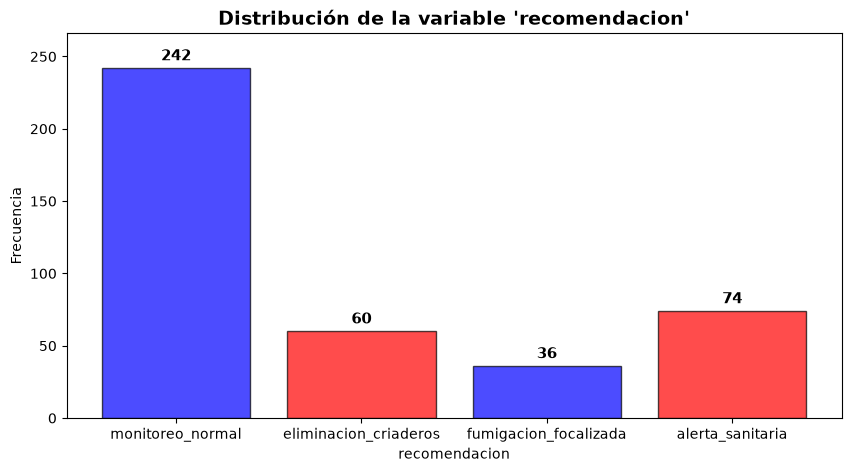

In [25]:
vectoria_acciones.graficos.plot_bar(escenario_2, 'recomendacion')

In [26]:
cantidades = escenario_2['recomendacion'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_2['recomendacion'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

58.74% de datos avarcados por la categoria monitoreo_normal
17.96% de datos avarcados por la categoria alerta_sanitaria
14.56% de datos avarcados por la categoria eliminacion_criaderos
8.74% de datos avarcados por la categoria fumigacion_focalizada


('0', '1')


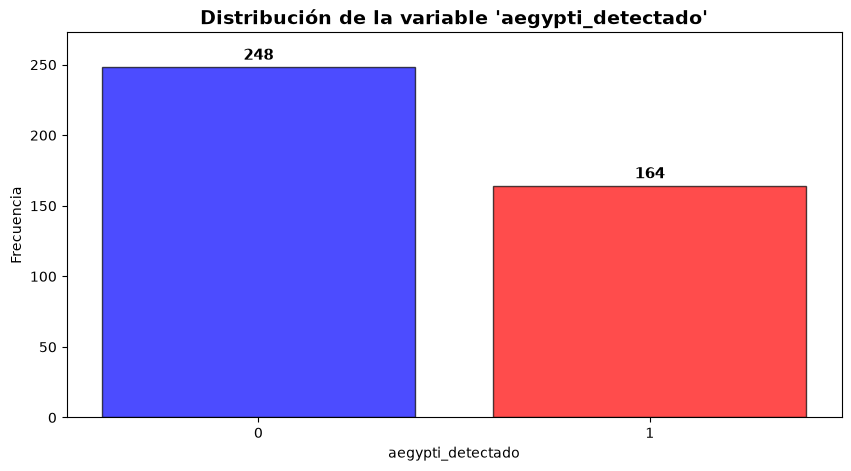

In [27]:
vectoria_acciones.graficos.plot_bar(escenario_2, 'aegypti_detectado')

In [28]:
cantidades = escenario_2['aegypti_detectado'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_2['aegypti_detectado'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

60.19% de datos avarcados por la categoria 0
39.81% de datos avarcados por la categoria 1


#### Escenario 3

In [29]:
escenario_3 = vectoria_acciones.data[vectoria_acciones.data['escenario'] == 3].drop(columns =['escenario'])
escenario_3

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
fecha_inicio_semana,,,,,,,,
2017-01-01,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2017-01-08,315,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
2017-01-15,332,1535,45.4,26.5,19.2,82.3,0,monitoreo_normal
2017-01-22,285,1319,1.1,27.0,18.7,81.1,0,monitoreo_normal
2017-01-29,271,1078,2.5,27.0,19.8,79.0,0,monitoreo_normal
...,...,...,...,...,...,...,...,...
2024-10-27,2092,1021,190.4,27.1,21.8,90.5,1,alerta_sanitaria
2024-11-03,1279,900,360.6,25.4,21.6,93.9,1,fumigacion_focalizada
2024-11-10,1575,759,719.8,24.4,21.2,94.9,1,alerta_sanitaria


In [30]:
escenario_3.drop(columns = ['aegypti_detectado', 'recomendacion']).describe()

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad
count,412.000000,412.000000,412.000000,412.000000,412.000000,412.000000
mean,983.087379,999.669903,113.226699,27.766505,21.105583,84.141748
std,1282.819489,604.172373,106.865353,1.663650,0.926544,7.375026
min,94.000000,210.000000,0.300000,24.400000,18.400000,64.300000
25%,228.000000,464.750000,32.125000,26.600000,20.500000,80.225000
50%,488.500000,871.000000,95.200000,27.300000,21.200000,87.000000
75%,1071.250000,1411.000000,163.350000,28.700000,21.800000,89.500000
max,7417.000000,2612.000000,867.600000,32.700000,23.200000,94.900000


('monitoreo_normal', 'eliminacion_criaderos', 'alerta_sanitaria', 'fumigacion_focalizada')


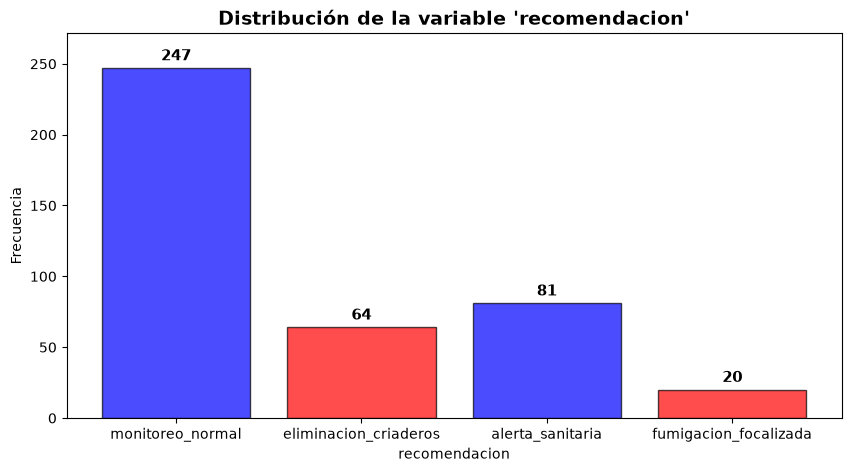

In [31]:
vectoria_acciones.graficos.plot_bar(escenario_3, 'recomendacion')

In [32]:
cantidades = escenario_3['recomendacion'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_3['recomendacion'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

59.95% de datos avarcados por la categoria monitoreo_normal
19.66% de datos avarcados por la categoria alerta_sanitaria
15.53% de datos avarcados por la categoria eliminacion_criaderos
4.85% de datos avarcados por la categoria fumigacion_focalizada


('0', '1')


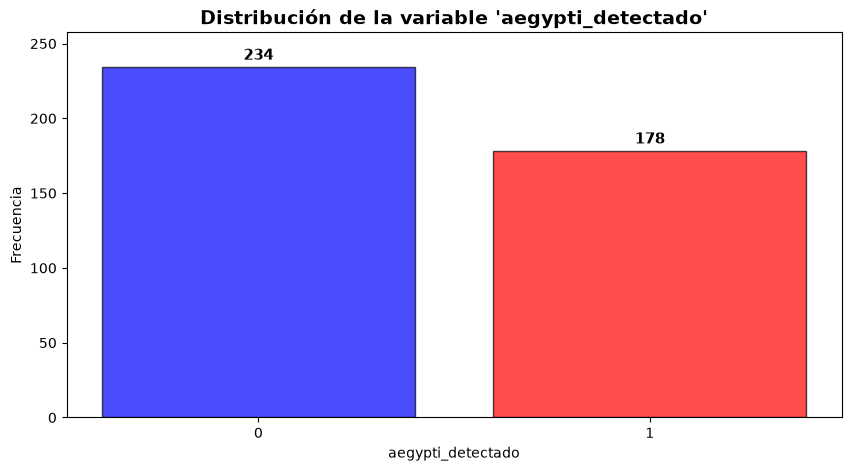

In [33]:
vectoria_acciones.graficos.plot_bar(escenario_3, 'aegypti_detectado')

In [34]:
cantidades = escenario_3['aegypti_detectado'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_3['aegypti_detectado'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

56.80% de datos avarcados por la categoria 0
43.20% de datos avarcados por la categoria 1


#### Escenario 4

In [35]:
escenario_4 = vectoria_acciones.data[vectoria_acciones.data['escenario'] == 4].drop(columns =['escenario'])
escenario_4

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
fecha_inicio_semana,,,,,,,,
2017-01-01,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2017-01-08,339,1720,59.2,26.3,20.2,84.4,1,monitoreo_normal
2017-01-15,376,1535,45.4,26.5,19.2,82.3,0,monitoreo_normal
2017-01-22,337,1319,1.1,27.0,18.7,81.1,0,monitoreo_normal
2017-01-29,230,1078,2.5,27.0,19.8,79.0,0,monitoreo_normal
...,...,...,...,...,...,...,...,...
2024-10-27,1800,1021,190.4,27.1,21.8,90.5,0,eliminacion_criaderos
2024-11-03,1324,900,360.6,25.4,21.6,93.9,1,fumigacion_focalizada
2024-11-10,2035,759,719.8,24.4,21.2,94.9,1,alerta_sanitaria


In [36]:
escenario_4.drop(columns = ['aegypti_detectado', 'recomendacion']).describe()

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad
count,412.000000,412.000000,412.000000,412.000000,412.000000,412.000000
mean,1023.936893,999.669903,113.226699,27.766505,21.105583,84.141748
std,1349.153048,604.172373,106.865353,1.663650,0.926544,7.375026
min,76.000000,210.000000,0.300000,24.400000,18.400000,64.300000
25%,250.750000,464.750000,32.125000,26.600000,20.500000,80.225000
50%,487.500000,871.000000,95.200000,27.300000,21.200000,87.000000
75%,1112.500000,1411.000000,163.350000,28.700000,21.800000,89.500000
max,7757.000000,2612.000000,867.600000,32.700000,23.200000,94.900000


('monitoreo_normal', 'eliminacion_criaderos', 'fumigacion_focalizada', 'alerta_sanitaria')


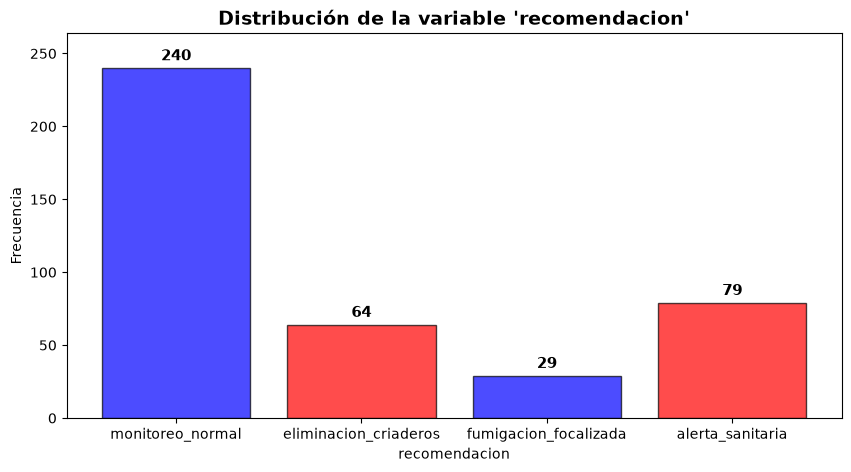

In [37]:
vectoria_acciones.graficos.plot_bar(escenario_4, 'recomendacion')

In [38]:
cantidades = escenario_4['recomendacion'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_4['recomendacion'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

58.25% de datos avarcados por la categoria monitoreo_normal
19.17% de datos avarcados por la categoria alerta_sanitaria
15.53% de datos avarcados por la categoria eliminacion_criaderos
7.04% de datos avarcados por la categoria fumigacion_focalizada


('0', '1')


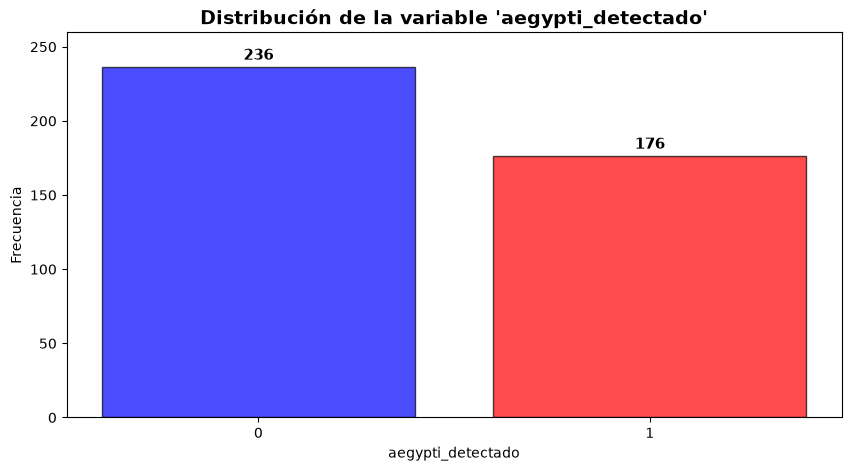

In [39]:
vectoria_acciones.graficos.plot_bar(escenario_4, 'aegypti_detectado')

In [40]:
cantidades = escenario_4['aegypti_detectado'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_4['aegypti_detectado'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

57.28% de datos avarcados por la categoria 0
42.72% de datos avarcados por la categoria 1


#### Escenario 5

In [41]:
escenario_5 = vectoria_acciones.data[vectoria_acciones.data['escenario'] == 5].drop(columns =['escenario'])
escenario_5

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
fecha_inicio_semana,,,,,,,,
2017-01-01,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2017-01-08,348,1720,59.2,26.3,20.2,84.4,0,monitoreo_normal
2017-01-15,329,1535,45.4,26.5,19.2,82.3,1,monitoreo_normal
2017-01-22,230,1319,1.1,27.0,18.7,81.1,0,monitoreo_normal
2017-01-29,273,1078,2.5,27.0,19.8,79.0,0,monitoreo_normal
...,...,...,...,...,...,...,...,...
2024-10-27,1249,1021,190.4,27.1,21.8,90.5,0,eliminacion_criaderos
2024-11-03,1563,900,360.6,25.4,21.6,93.9,1,fumigacion_focalizada
2024-11-10,1192,759,719.8,24.4,21.2,94.9,1,fumigacion_focalizada


In [42]:
escenario_5.drop(columns = ['aegypti_detectado', 'recomendacion']).describe()

,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad
count,412.000000,412.000000,412.000000,412.000000,412.000000,412.000000
mean,1024.754854,999.669903,113.226699,27.766505,21.105583,84.141748
std,1382.404843,604.172373,106.865353,1.663650,0.926544,7.375026
min,83.000000,210.000000,0.300000,24.400000,18.400000,64.300000
25%,244.000000,464.750000,32.125000,26.600000,20.500000,80.225000
50%,521.500000,871.000000,95.200000,27.300000,21.200000,87.000000
75%,1063.500000,1411.000000,163.350000,28.700000,21.800000,89.500000
max,7736.000000,2612.000000,867.600000,32.700000,23.200000,94.900000


('monitoreo_normal', 'eliminacion_criaderos', 'alerta_sanitaria', 'fumigacion_focalizada')


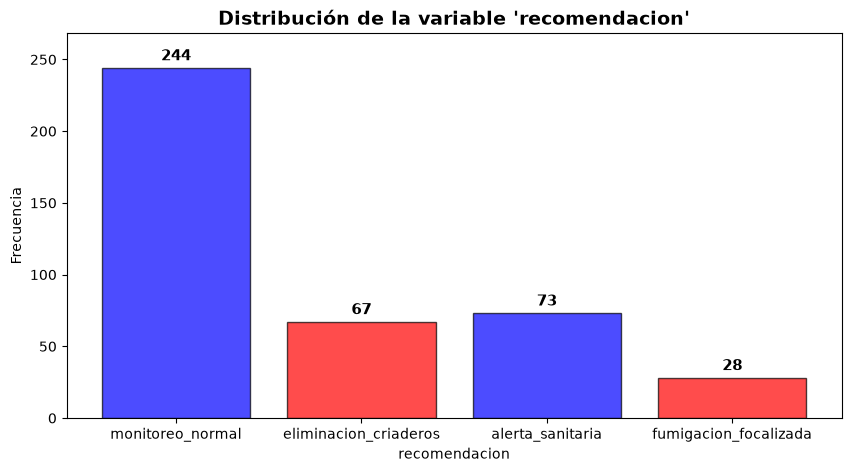

In [43]:
vectoria_acciones.graficos.plot_bar(escenario_5, 'recomendacion')

In [44]:
cantidades = escenario_5['recomendacion'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_5['recomendacion'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

59.22% de datos avarcados por la categoria monitoreo_normal
17.72% de datos avarcados por la categoria alerta_sanitaria
16.26% de datos avarcados por la categoria eliminacion_criaderos
6.80% de datos avarcados por la categoria fumigacion_focalizada


('0', '1')


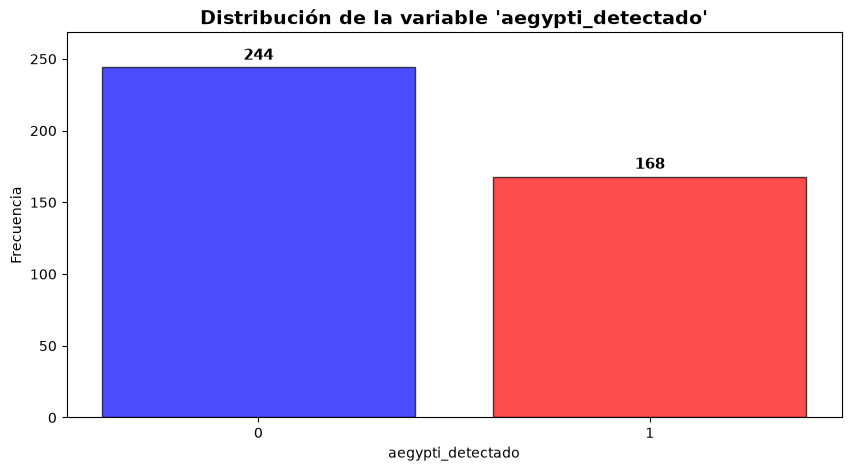

In [45]:
vectoria_acciones.graficos.plot_bar(escenario_5, 'aegypti_detectado')

In [46]:
cantidades = escenario_5['aegypti_detectado'].value_counts().to_frame()

cantidades_indx = list(cantidades.index)

for indx in cantidades_indx:
    valor = int(cantidades.loc[indx].to_numpy()[0])
    
    print(f'{(valor/escenario_5['aegypti_detectado'].count())*100:.2f}% de datos avarcados por la categoria {indx}')

59.22% de datos avarcados por la categoria 0
40.78% de datos avarcados por la categoria 1


### Correlaciones

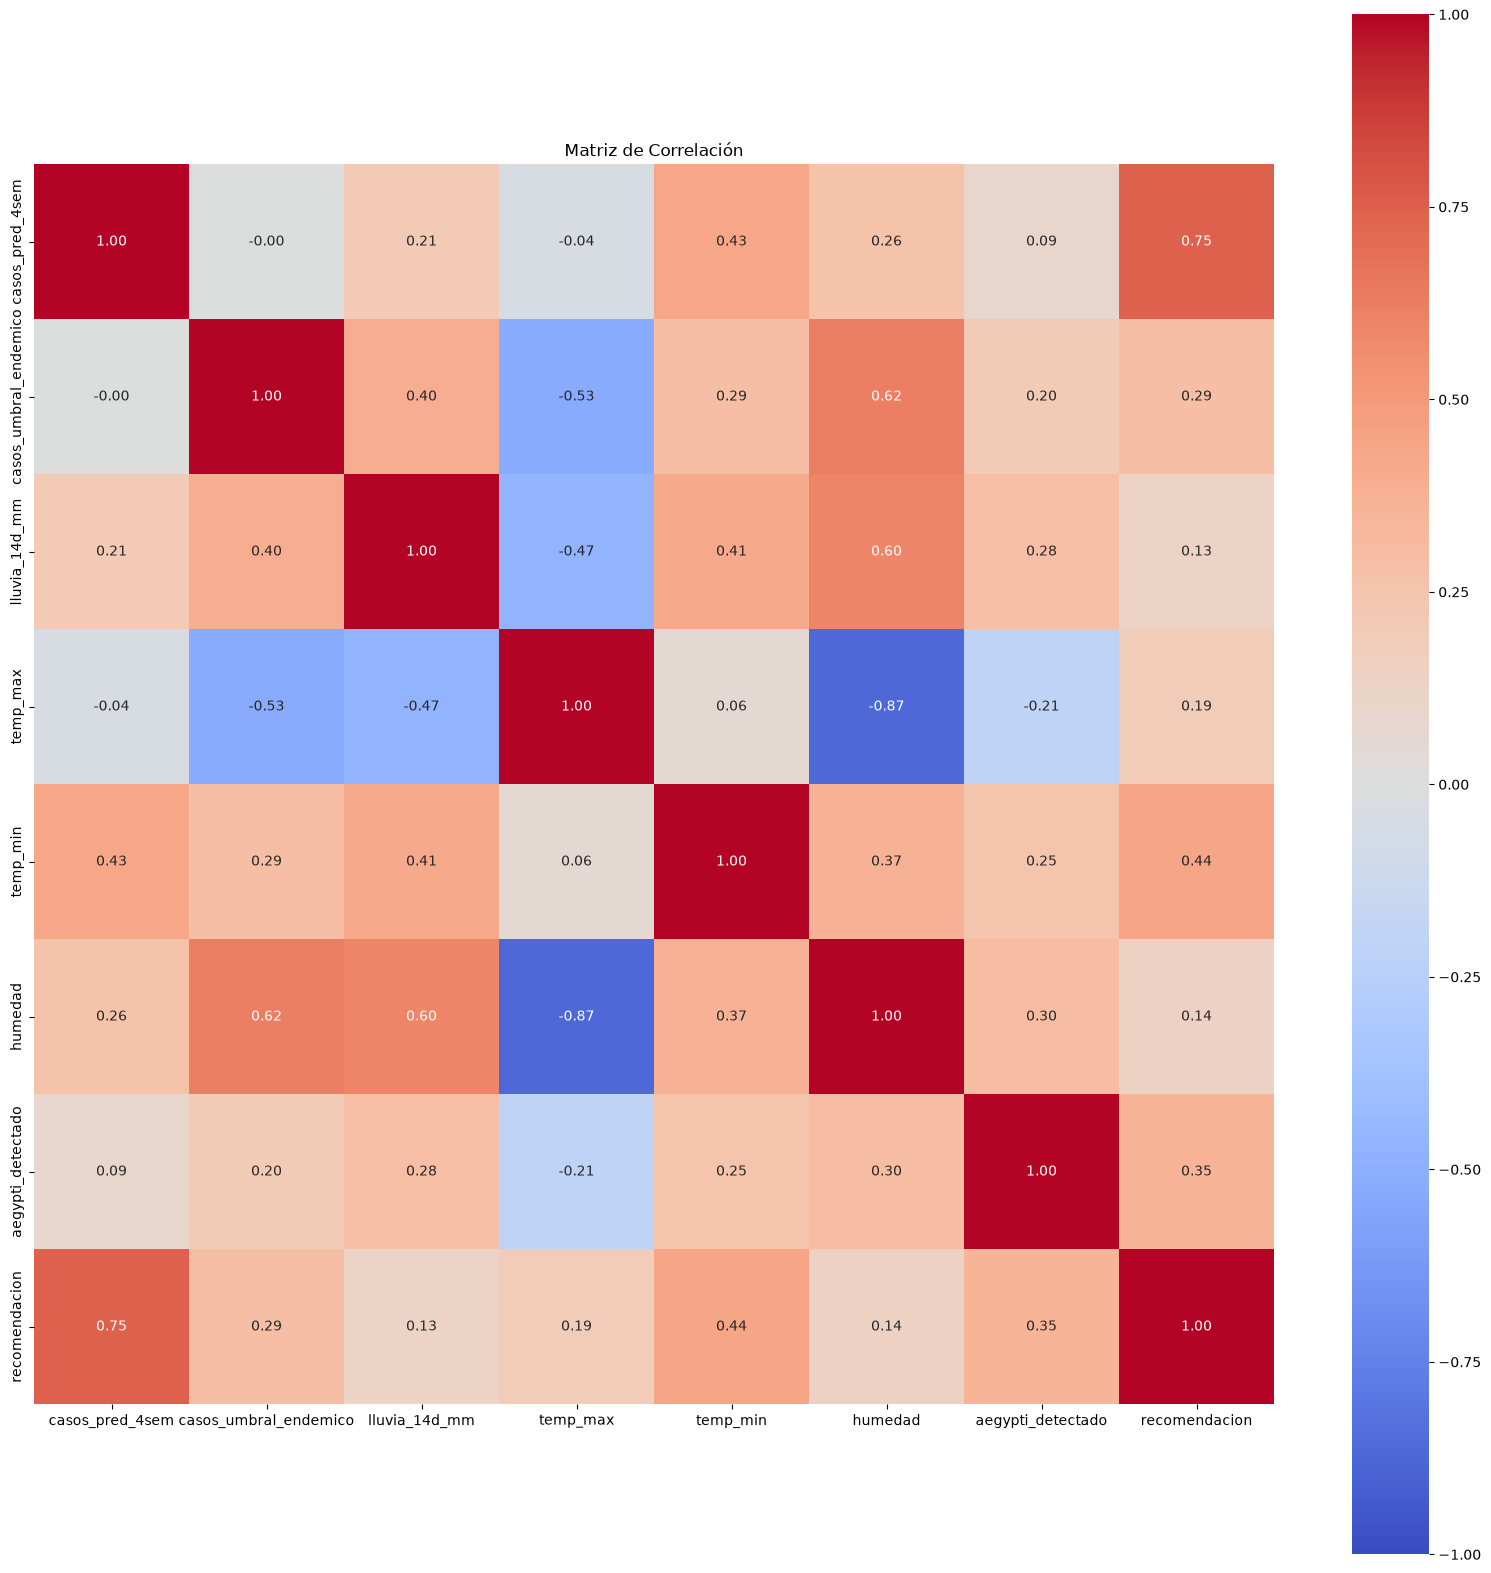

In [47]:
vectoria_acciones.graficos.corr(escenario_1)

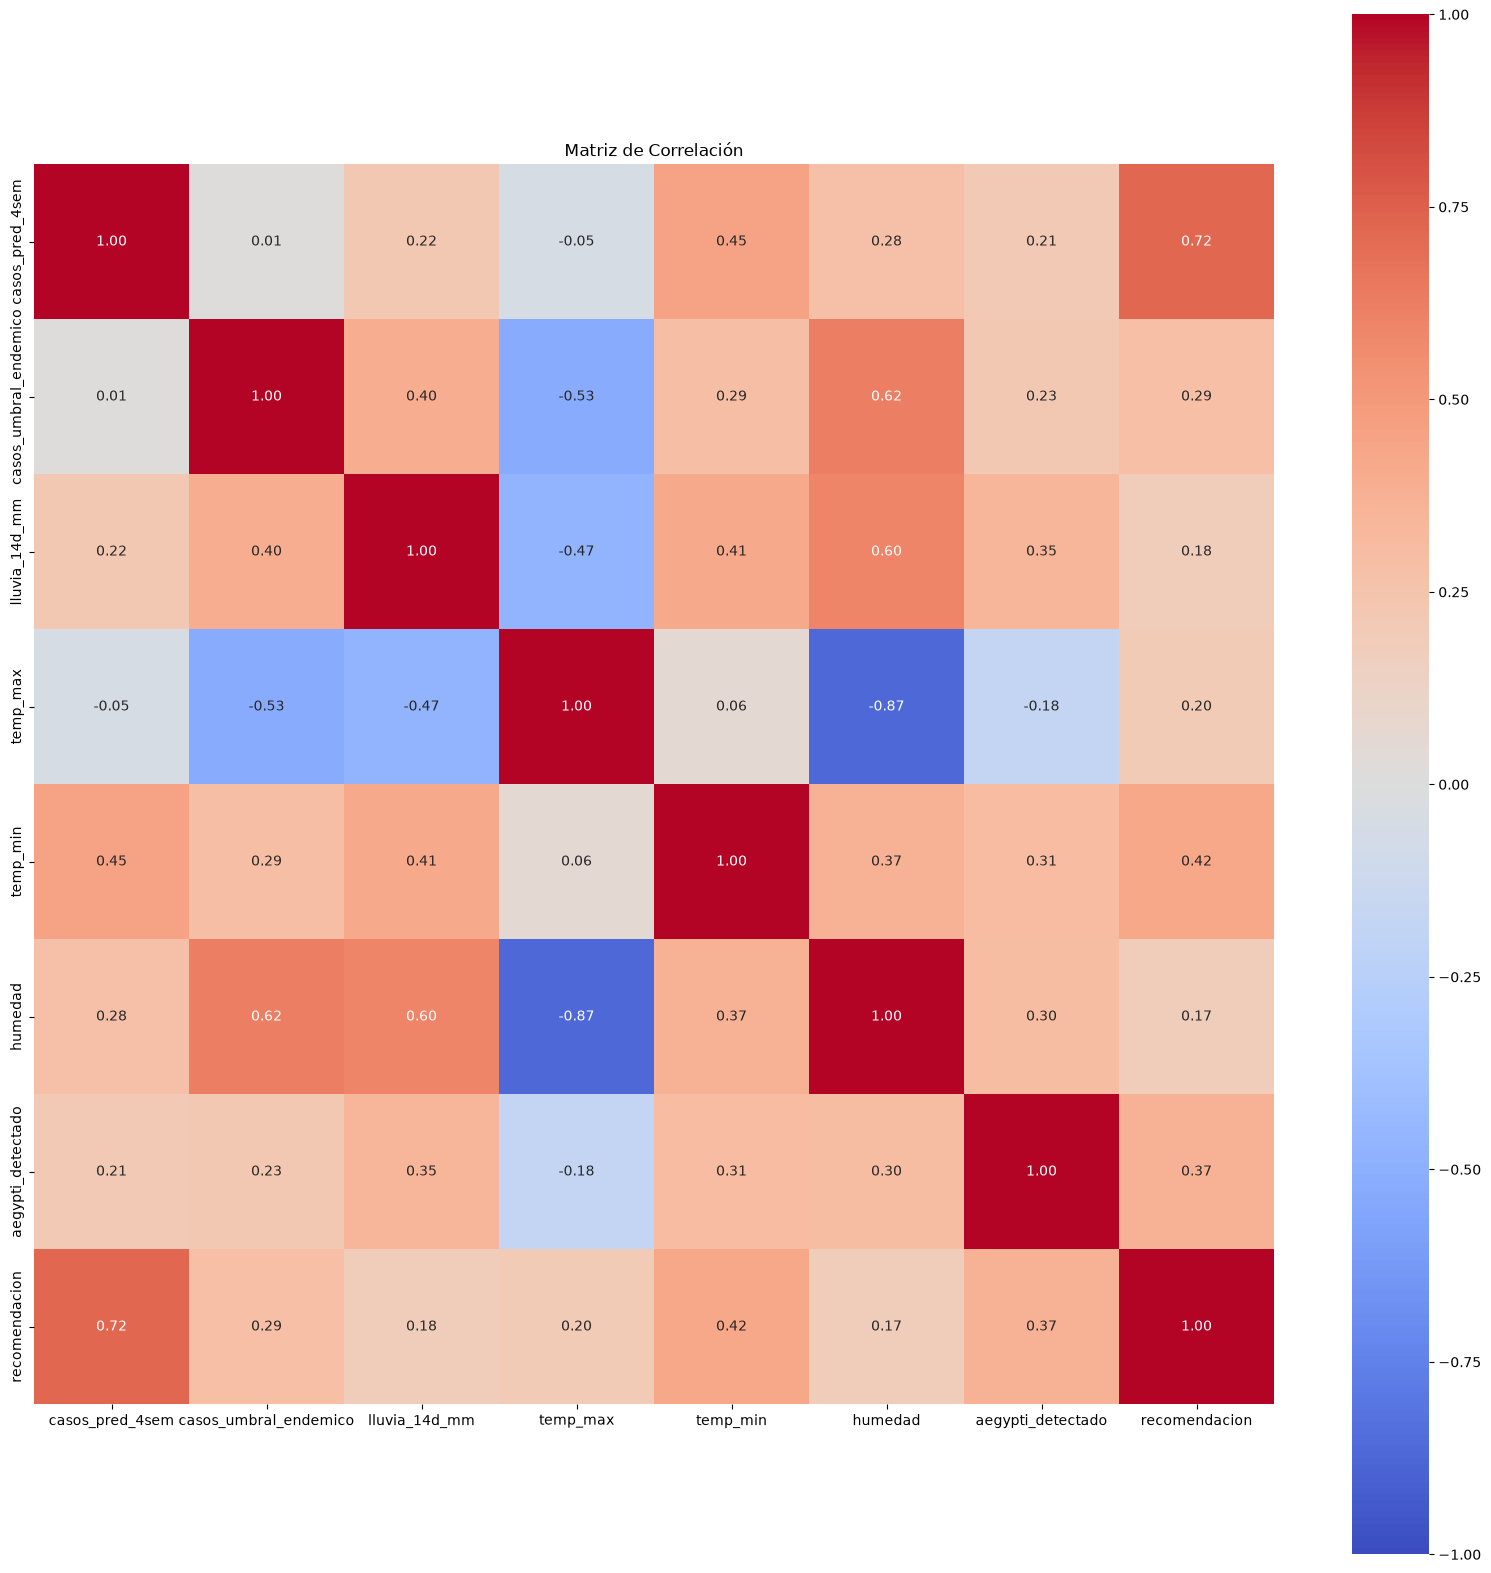

In [48]:
vectoria_acciones.graficos.corr(escenario_2)

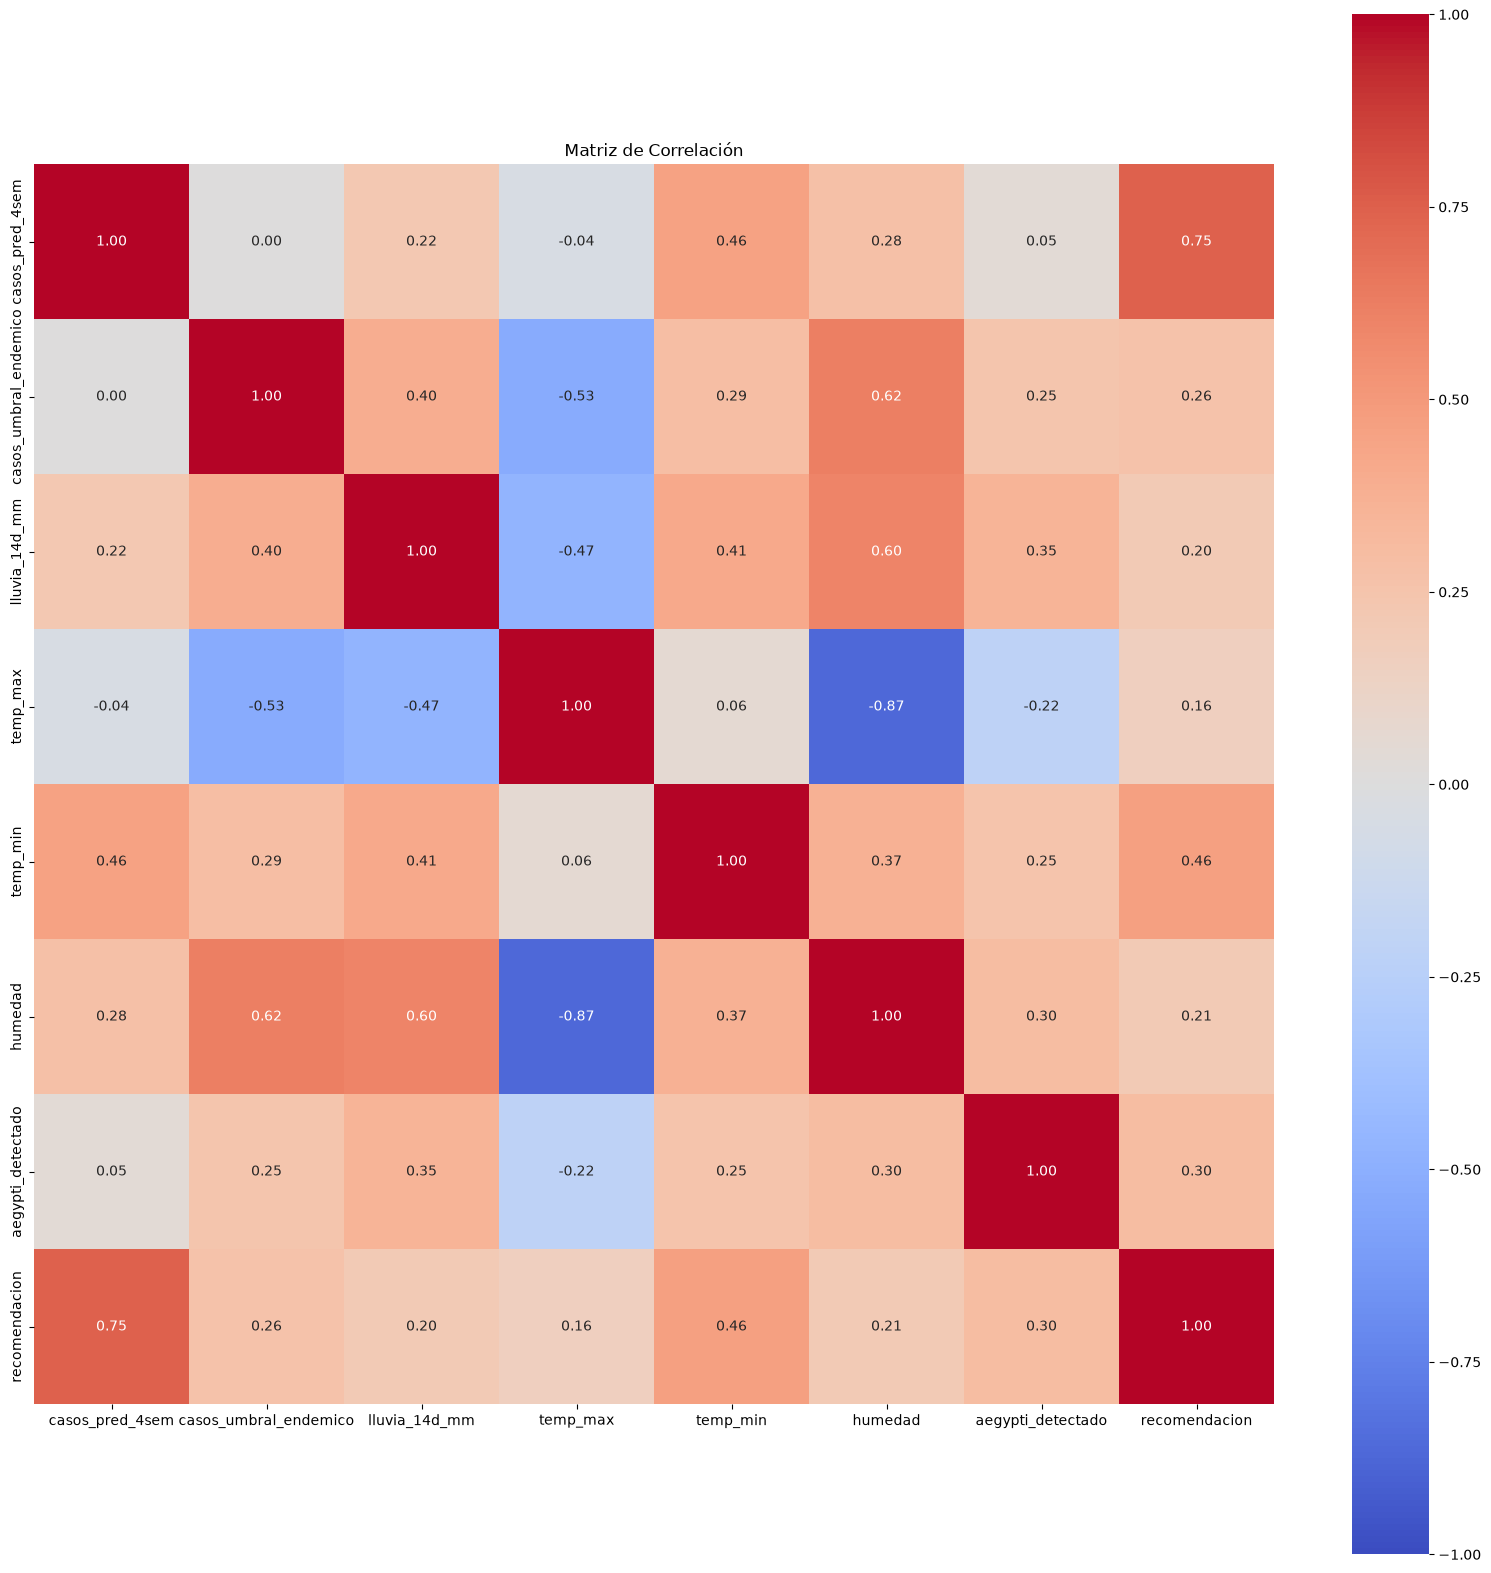

In [49]:
vectoria_acciones.graficos.corr(escenario_3)

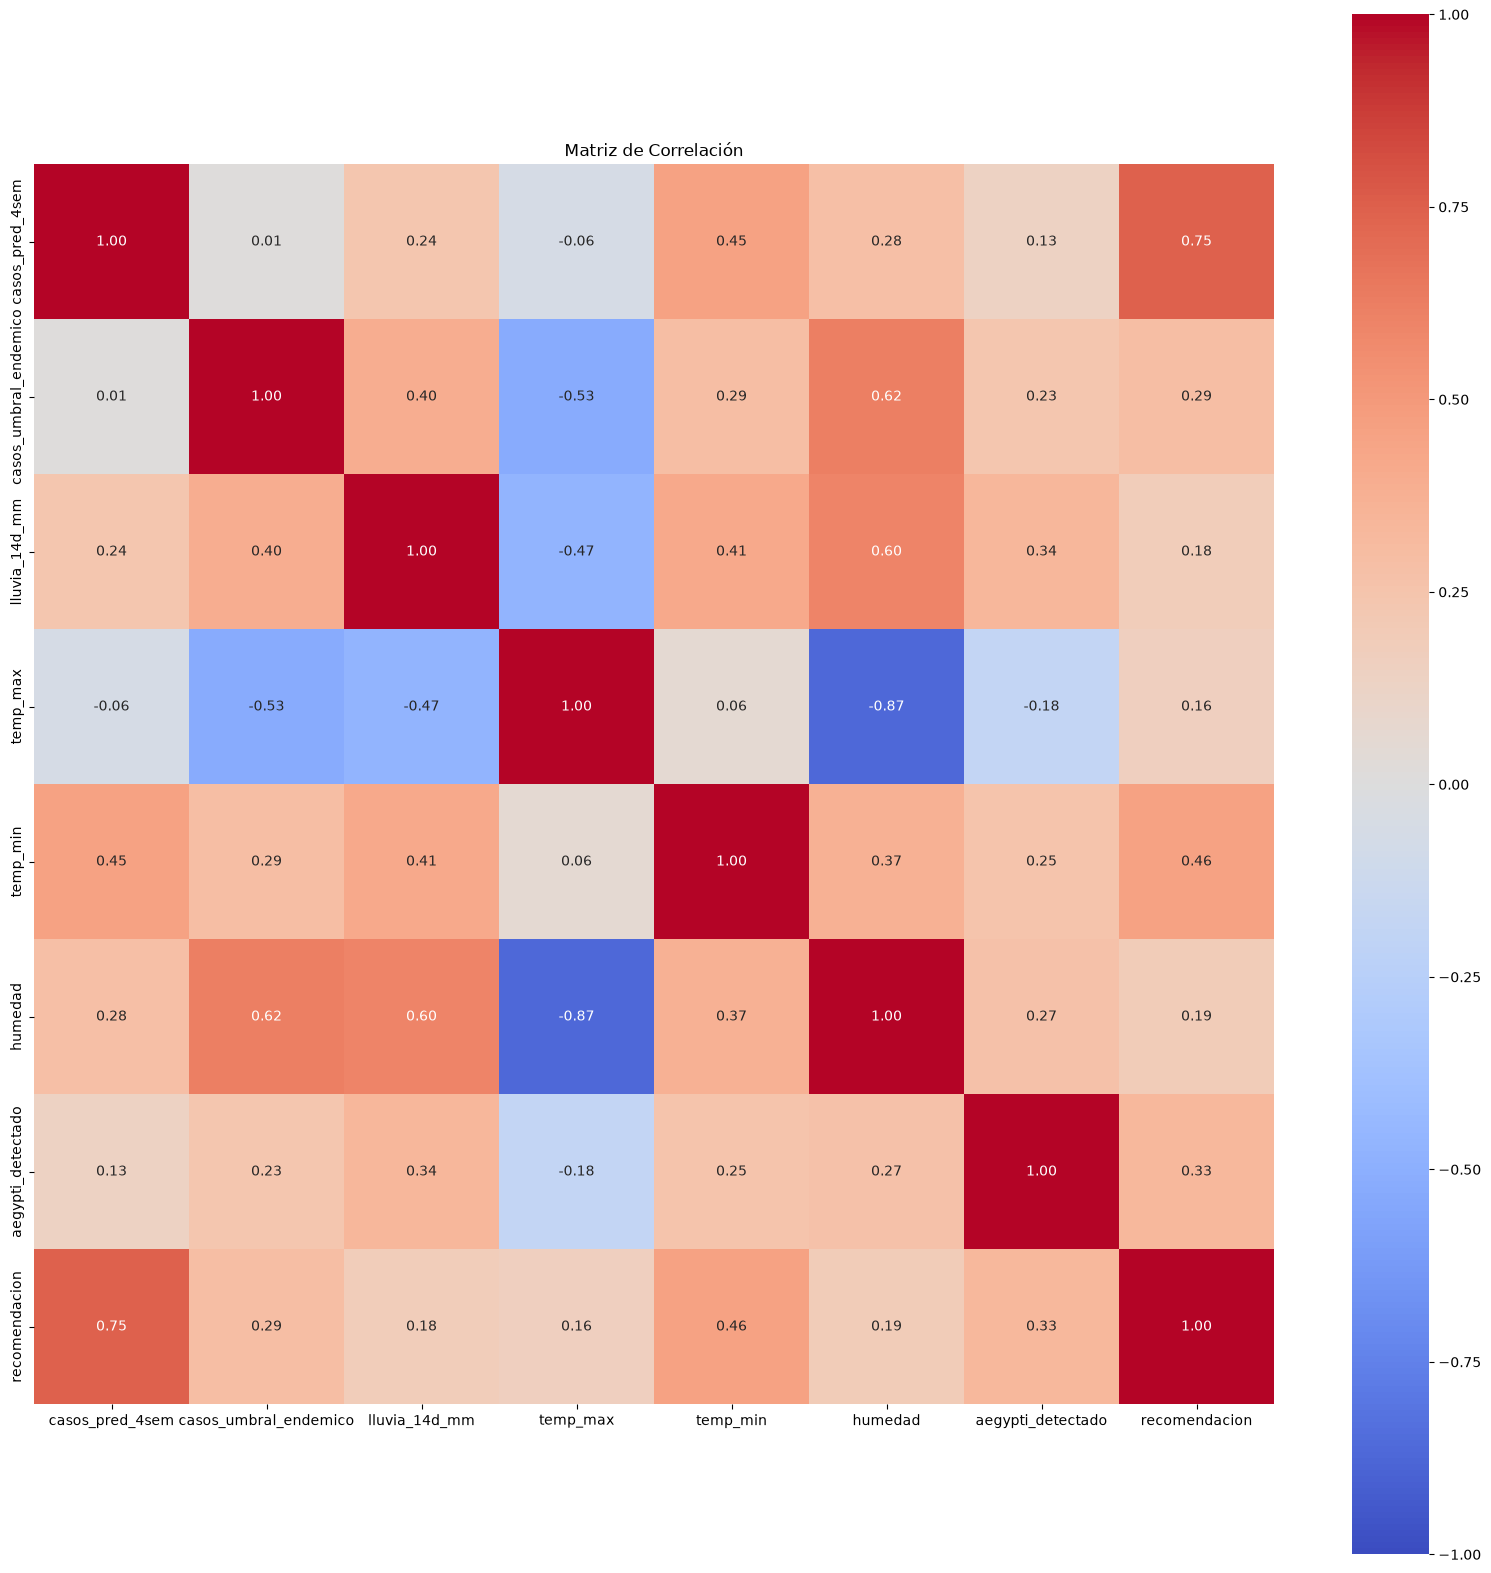

In [50]:
vectoria_acciones.graficos.corr(escenario_4)

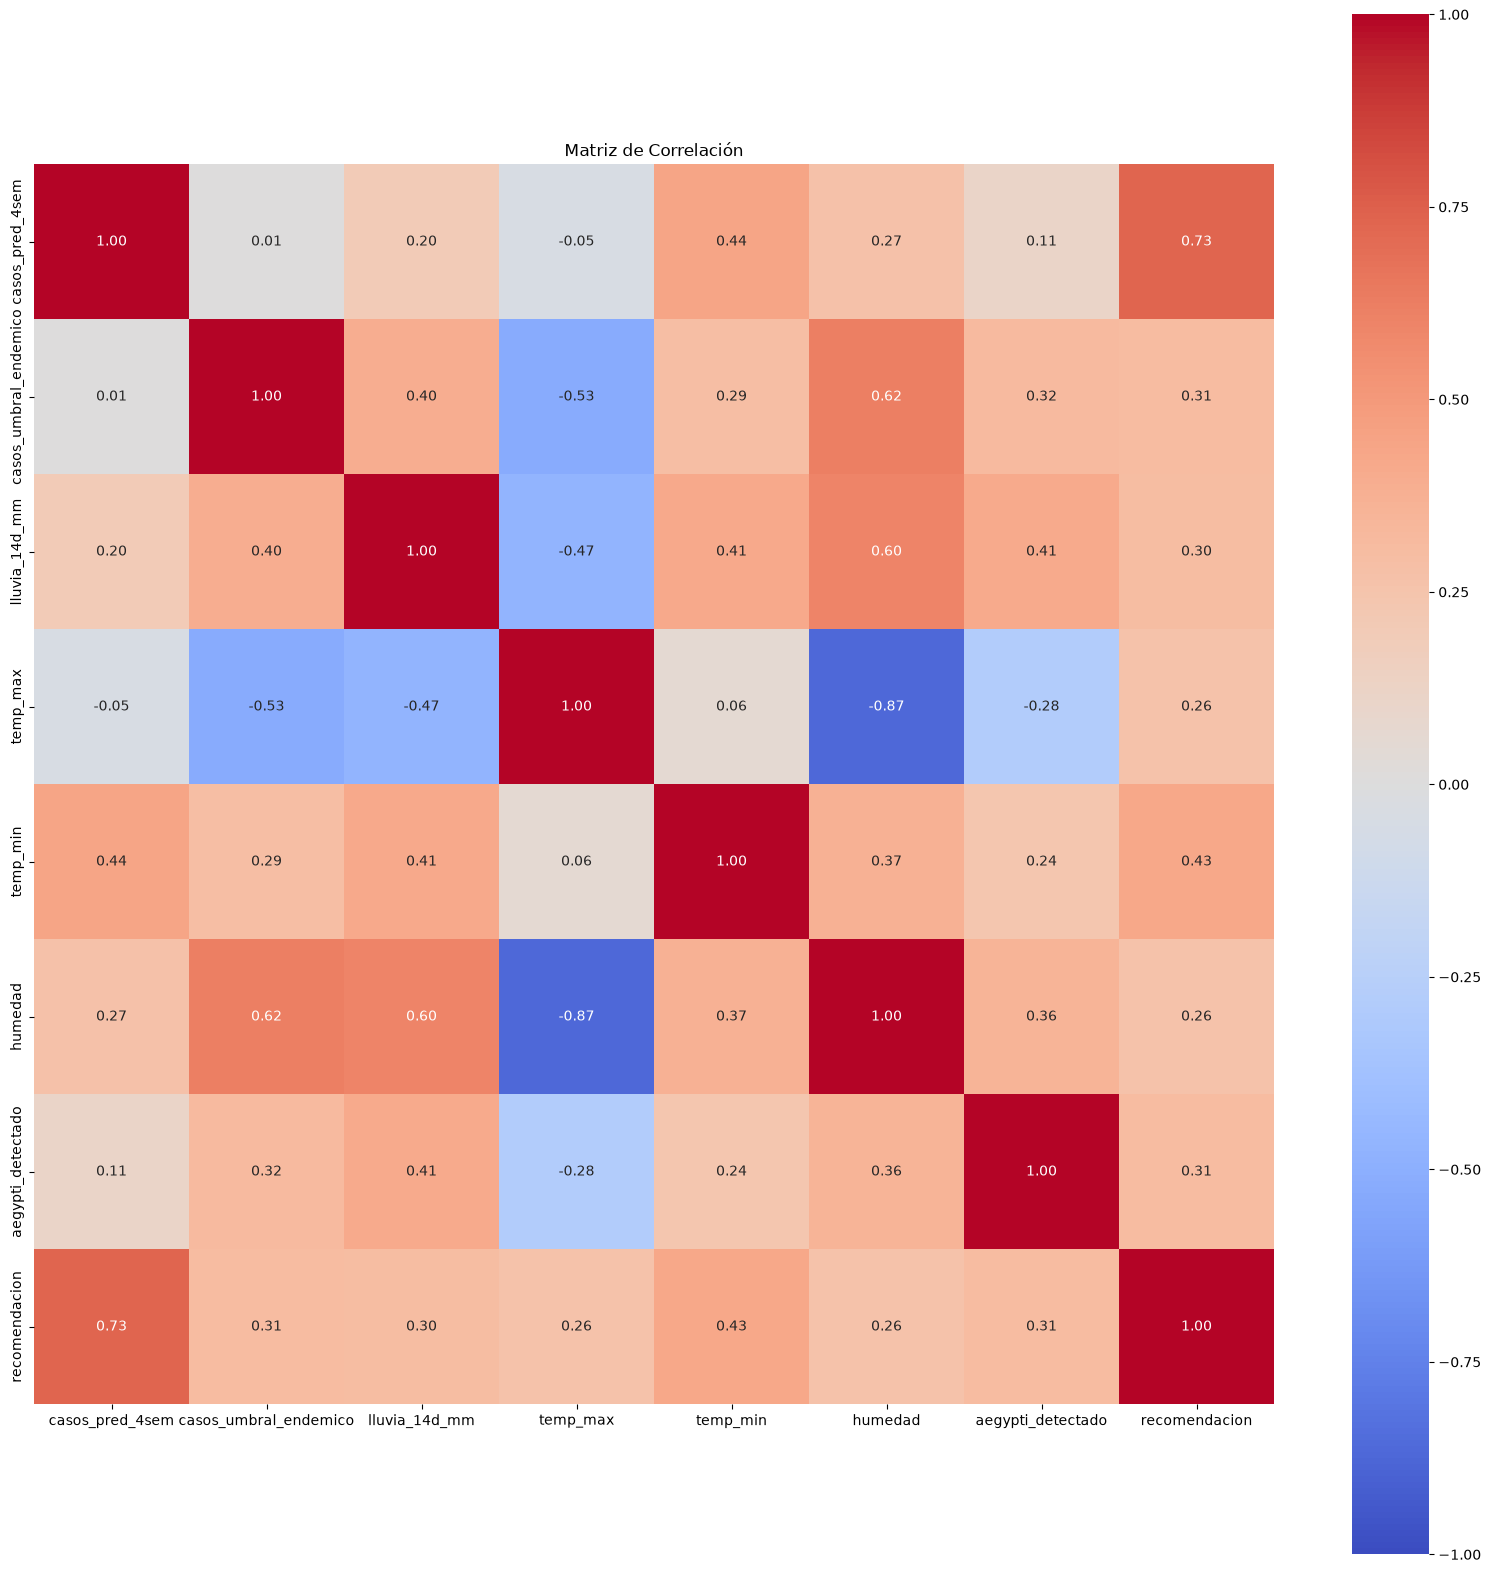

In [51]:
vectoria_acciones.graficos.corr(escenario_5)

Los datos entre escenarios se mantienen con mertricas similares, por lo que en la particion de estos para el proceso de entrenamineto se deben de considerar el tratarla para evitar fitracion de datos entre escenarios como confirma el README de los datos.

## Analisis de vectoria_casos_cantonal_anual_real

In [52]:
vectoria_casos_cantonal_anual_real.data['anio'] = vectoria_casos_cantonal_anual_real.data['anio']
vectoria_casos_cantonal_anual_real.data = vectoria_casos_cantonal_anual_real.data.set_index('anio')


vectoria_casos_cantonal_anual_real.data.shape

(422, 3)

In [53]:

vectoria_casos_cantonal_anual_real.data

,provincia,canton,casos_dengue
anio,,,
2013,Alajuela,Alfaro Ruiz,4
2013,Alajuela,Atenas,3722
2013,Alajuela,Grecia,846
2013,Alajuela,Guatuso,30
2013,Alajuela,Los Chiles,10
...,...,...,...
2018,San José,Puriscal,2
2018,San José,San Jose,78
2018,San José,Santa Ana,0


In [54]:
vectoria_casos_cantonal_anual_real.data.info()

<class 'pandas.DataFrame'>
Index: 422 entries, 2013 to 2018
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   provincia     422 non-null    str  
 1   canton        422 non-null    str  
 2   casos_dengue  422 non-null    int64
dtypes: int64(1), str(2)
memory usage: 20.0 KB


In [55]:
vectoria_casos_cantonal_anual_real.data.nunique()

provincia         7
canton           72
casos_dengue    200
dtype: int64

### Mapa de calor de los casos de dengue por canton cantones

#### Acumulado

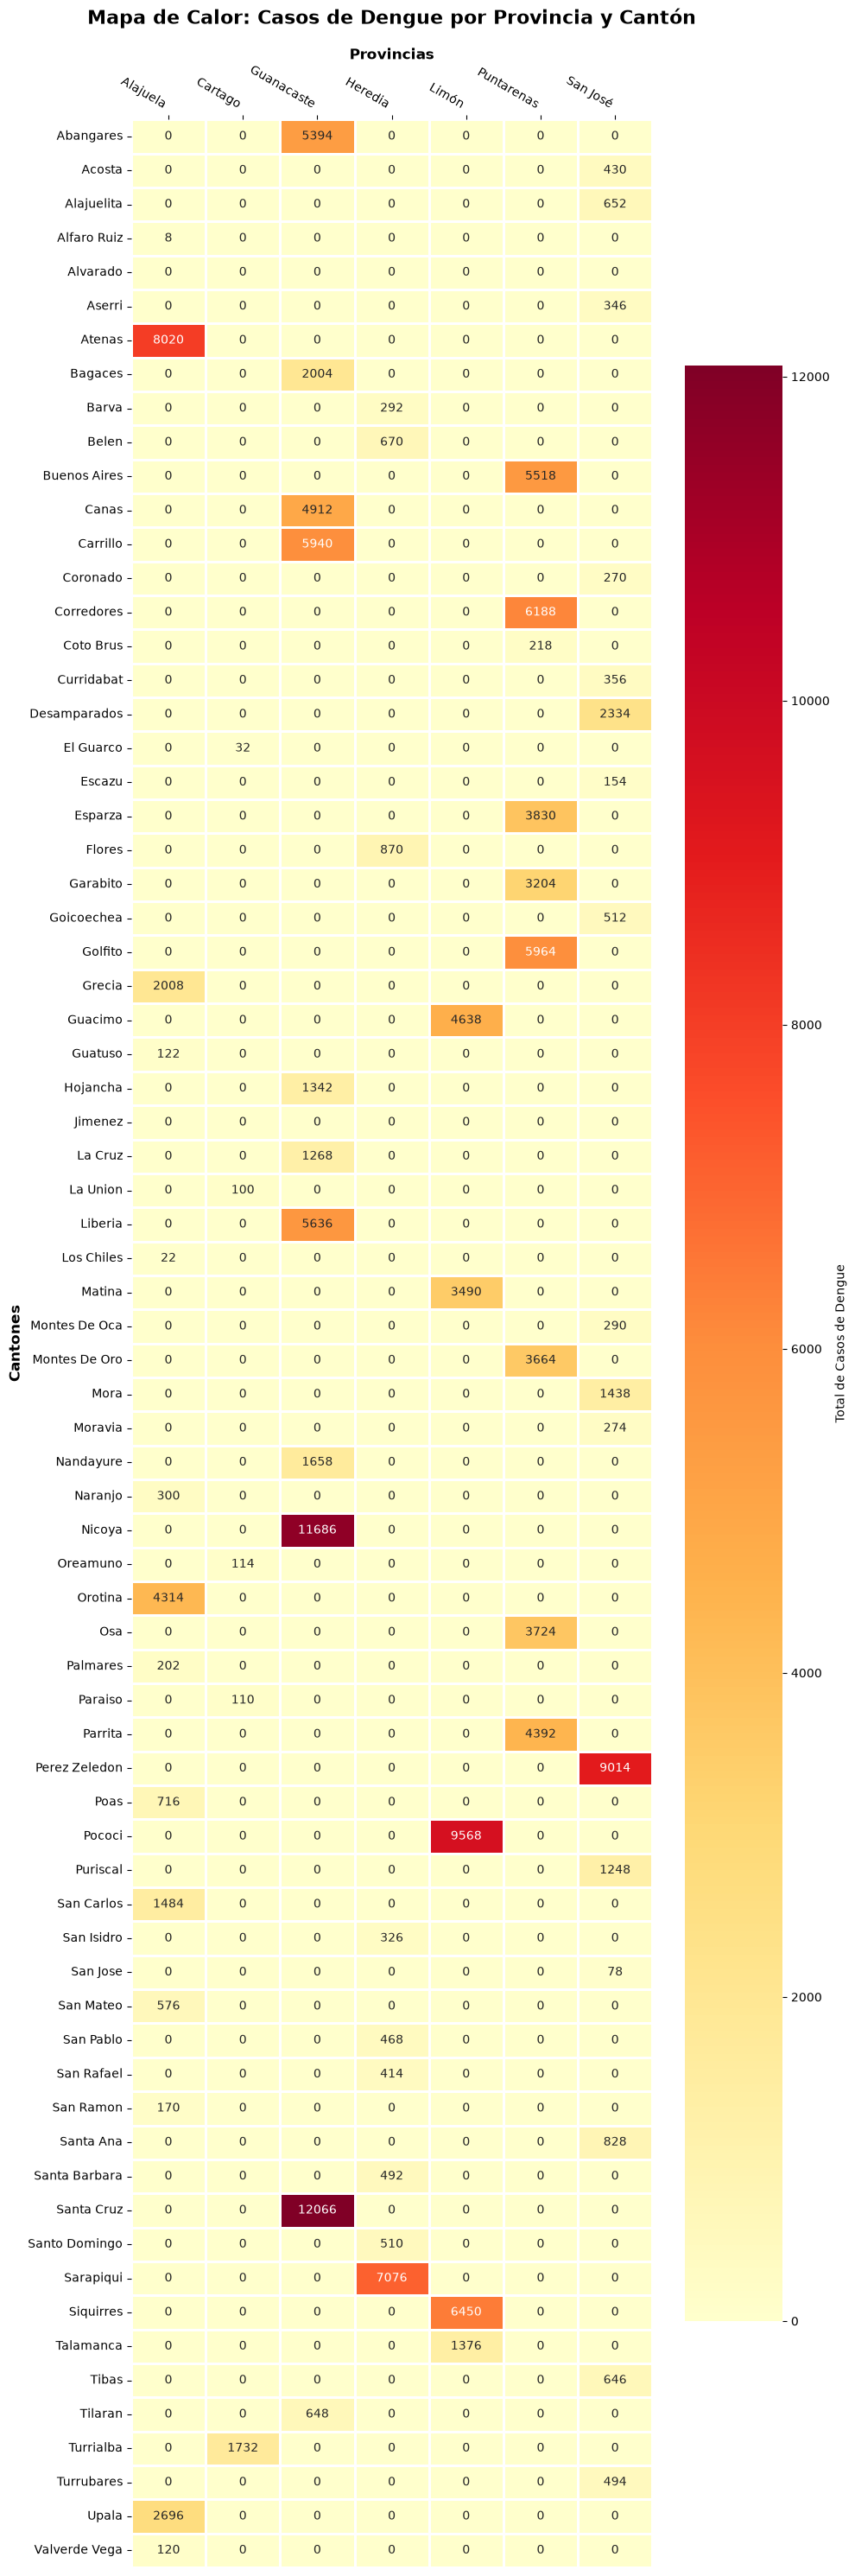

In [56]:
matriz_dengue = vectoria_casos_cantonal_anual_real.data.pivot_table(
    index='canton',      # Se convierte en las filas del mapa de calor
    columns='provincia',       # Se convierte en las columnas
    values='casos_dengue',  # El dato numérico que llenará las celdas
    aggfunc='sum',          # Suma los casos si un cantón aparece en varios años
    fill_value=0            # Rellena con 0 si un cantón no tiene registros
)

vectoria_casos_cantonal_anual_real.graficos.heatmap(
    matriz_dengue,
    "Mapa de Calor: Casos de Dengue por Provincia y Cantón",
    'Total de Casos de Dengue',
    "Provincias",
    "Cantones",
    10,
    30,
    -30
    )

#### Promedio

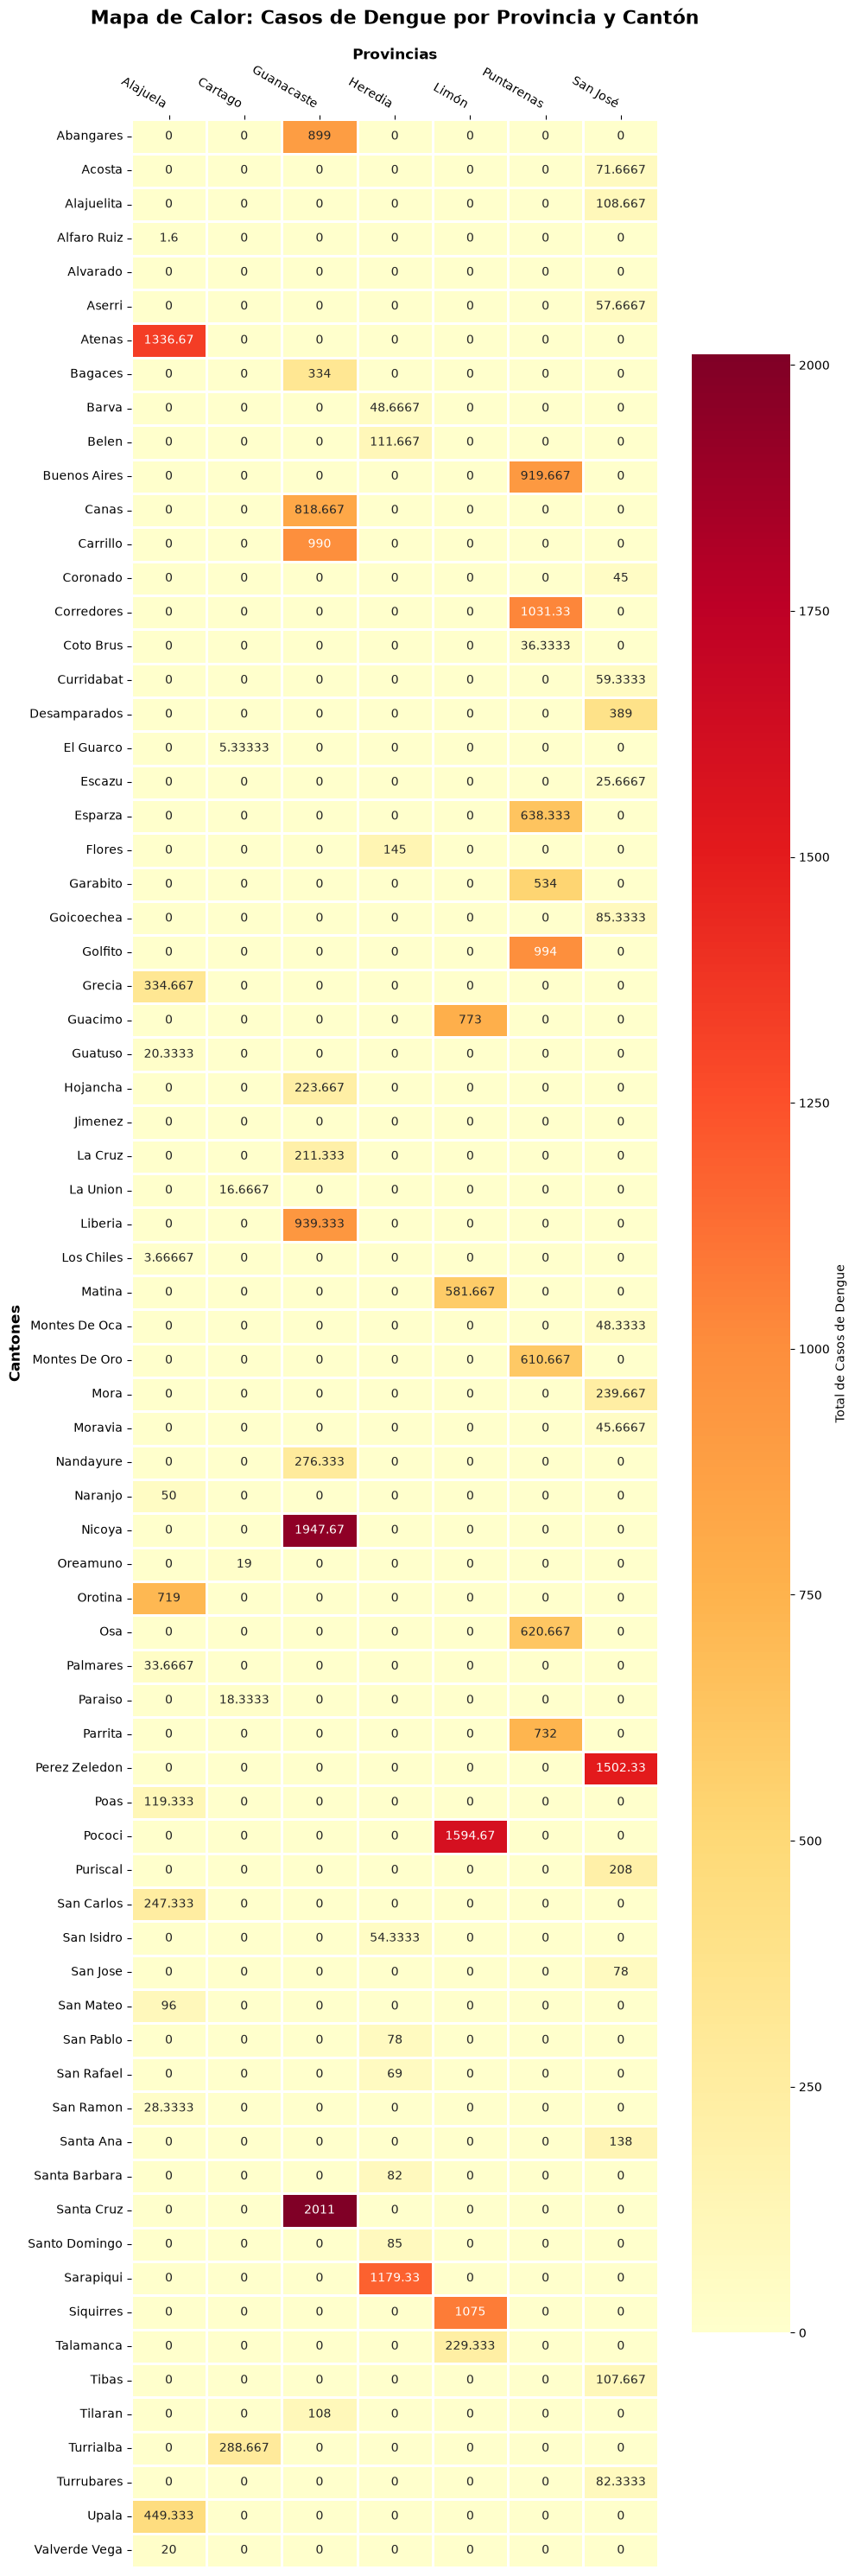

In [57]:
matriz_dengue = vectoria_casos_cantonal_anual_real.data.pivot_table(
    index='canton',      # Se convierte en las filas del mapa de calor
    columns='provincia',       # Se convierte en las columnas
    values='casos_dengue',  # El dato numérico que llenará las celdas
    aggfunc='mean',          # Promedia los casos si un cantón aparece en varios años
    fill_value=0            # Rellena con 0 si un cantón no tiene registros
)

vectoria_casos_cantonal_anual_real.graficos.heatmap(
    matriz_dengue,
    "Mapa de Calor: Casos de Dengue por Provincia y Cantón",
    'Total de Casos de Dengue',
    "Provincias",
    "Cantones",
    10,
    30,
    -30
    )

### Visualizacion en mapa geografico

In [58]:
#vectoria_casos_cantonal_anual_real.graficos.generar_mapa(datos = vectoria_casos_cantonal_anual_real.data, col_provincia = 'provincia', col_canton = 'canton', col_escala = 'casos_dengue' )

In [59]:
from IPython.display import IFrame

# Carga mapa interactivo en una ventana interna
# Se puede ajustar el 'width' (ancho) y 'height' (alto) en píxeles
IFrame(src="mapa_calor_dengue_completo.html", width="100%", height=500)

## Analisis de vectoria_dengue_nacional_real

In [60]:
vectoria_dengue_nacional_real.data['fecha_inicio_semana'] = pd.to_datetime(vectoria_dengue_nacional_real.data['fecha_inicio_semana'])
vectoria_dengue_nacional_real.data = vectoria_dengue_nacional_real.data.set_index('fecha_inicio_semana')


vectoria_dengue_nacional_real.data.shape

(574, 11)

In [61]:

vectoria_dengue_nacional_real.data

,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
fecha_inicio_semana,,,,,,,,,,,
2013-12-29,2014,1,Costa Rica,Nacional,5170000,239,4.62,11.0,27.2,19.9,84.9
2014-01-05,2014,2,Costa Rica,Nacional,5170000,257,4.97,8.9,27.0,19.7,83.8
2014-01-12,2014,3,Costa Rica,Nacional,5170000,184,3.56,4.5,27.1,19.5,81.7
2014-01-19,2014,4,Costa Rica,Nacional,5170000,156,3.02,7.7,27.1,19.5,80.0
2014-01-26,2014,5,Costa Rica,Nacional,5170000,189,3.66,4.7,27.2,18.7,78.0
...,...,...,...,...,...,...,...,...,...,...,...
2024-11-24,2024,48,Costa Rica,Nacional,5170000,402,7.78,64.9,26.7,21.2,91.4
2024-12-01,2024,49,Costa Rica,Nacional,5170000,340,6.58,35.4,26.7,21.1,88.7
2024-12-08,2024,50,Costa Rica,Nacional,5170000,312,6.03,14.5,27.6,21.1,85.7


In [62]:
vectoria_dengue_nacional_real.data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 574 entries, 2013-12-29 to 2024-12-22
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   anio              574 non-null    int64  
 1   semana_epi        574 non-null    int64  
 2   provincia         574 non-null    str    
 3   region_climatica  574 non-null    str    
 4   poblacion         574 non-null    int64  
 5   casos_dengue      574 non-null    int64  
 6   tasa_100k         574 non-null    float64
 7   lluvia_mm         574 non-null    float64
 8   temp_max_c        574 non-null    float64
 9   temp_min_c        574 non-null    float64
 10  humedad_rel_pct   574 non-null    float64
dtypes: float64(5), int64(4), str(2)
memory usage: 63.9 KB


In [63]:
vectoria_dengue_nacional_real.data.nunique()

anio                 11
semana_epi           53
provincia             1
region_climatica      1
poblacion             1
casos_dengue        347
tasa_100k           347
lluvia_mm           444
temp_max_c           79
temp_min_c           48
humedad_rel_pct     227
dtype: int64

<Axes: xlabel='fecha_inicio_semana'>

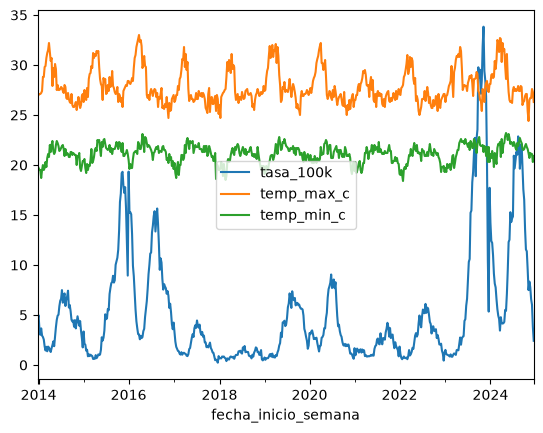

In [64]:
vectoria_dengue_nacional_real.data.drop(columns= ['poblacion', 'lluvia_mm', 'casos_dengue', 'humedad_rel_pct', 'semana_epi', 'anio']).plot()

<Axes: xlabel='fecha_inicio_semana'>

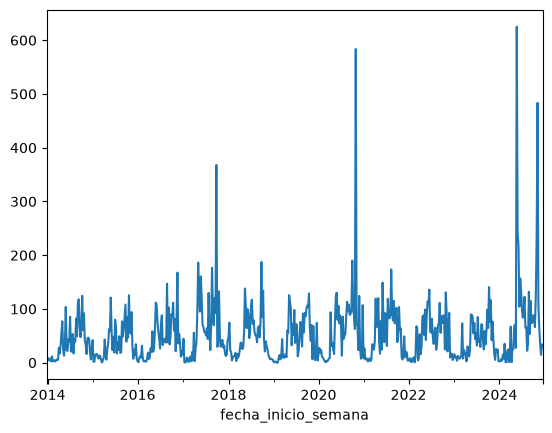

In [65]:
vectoria_dengue_nacional_real.data['lluvia_mm'].plot()

<Axes: xlabel='fecha_inicio_semana'>

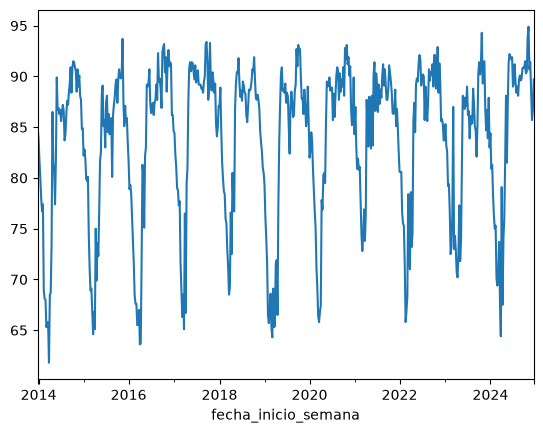

In [66]:
vectoria_dengue_nacional_real.data['humedad_rel_pct'].plot()

In [67]:
vectoria_dengue_nacional_real.data.drop(columns = ['anio', 'semana_epi', 'tasa_100k'] , inplace = True)

/tmp/ipykernel_134566/887708460.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  vectoria_dengue_nacional_real.data.drop(columns = ['anio', 'semana_epi', 'tasa_100k'] , inplace = True)


In [68]:
vectoria_dengue_nacional_real.data.describe()

,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
count,574.0,574.000000,574.000000,574.000000,574.000000,574.000000
mean,5170000.0,268.592334,51.967422,27.836237,21.121777,83.722125
std,0.0,304.173514,57.637724,1.712996,0.906615,7.658415
min,5170000.0,12.000000,0.000000,24.400000,18.400000,61.800000
25%,5170000.0,71.000000,13.575000,26.700000,20.500000,79.425000
50%,5170000.0,156.000000,38.500000,27.400000,21.200000,86.700000
75%,5170000.0,328.000000,75.400000,28.700000,21.800000,89.300000
max,5170000.0,1749.000000,625.200000,33.000000,23.200000,94.900000


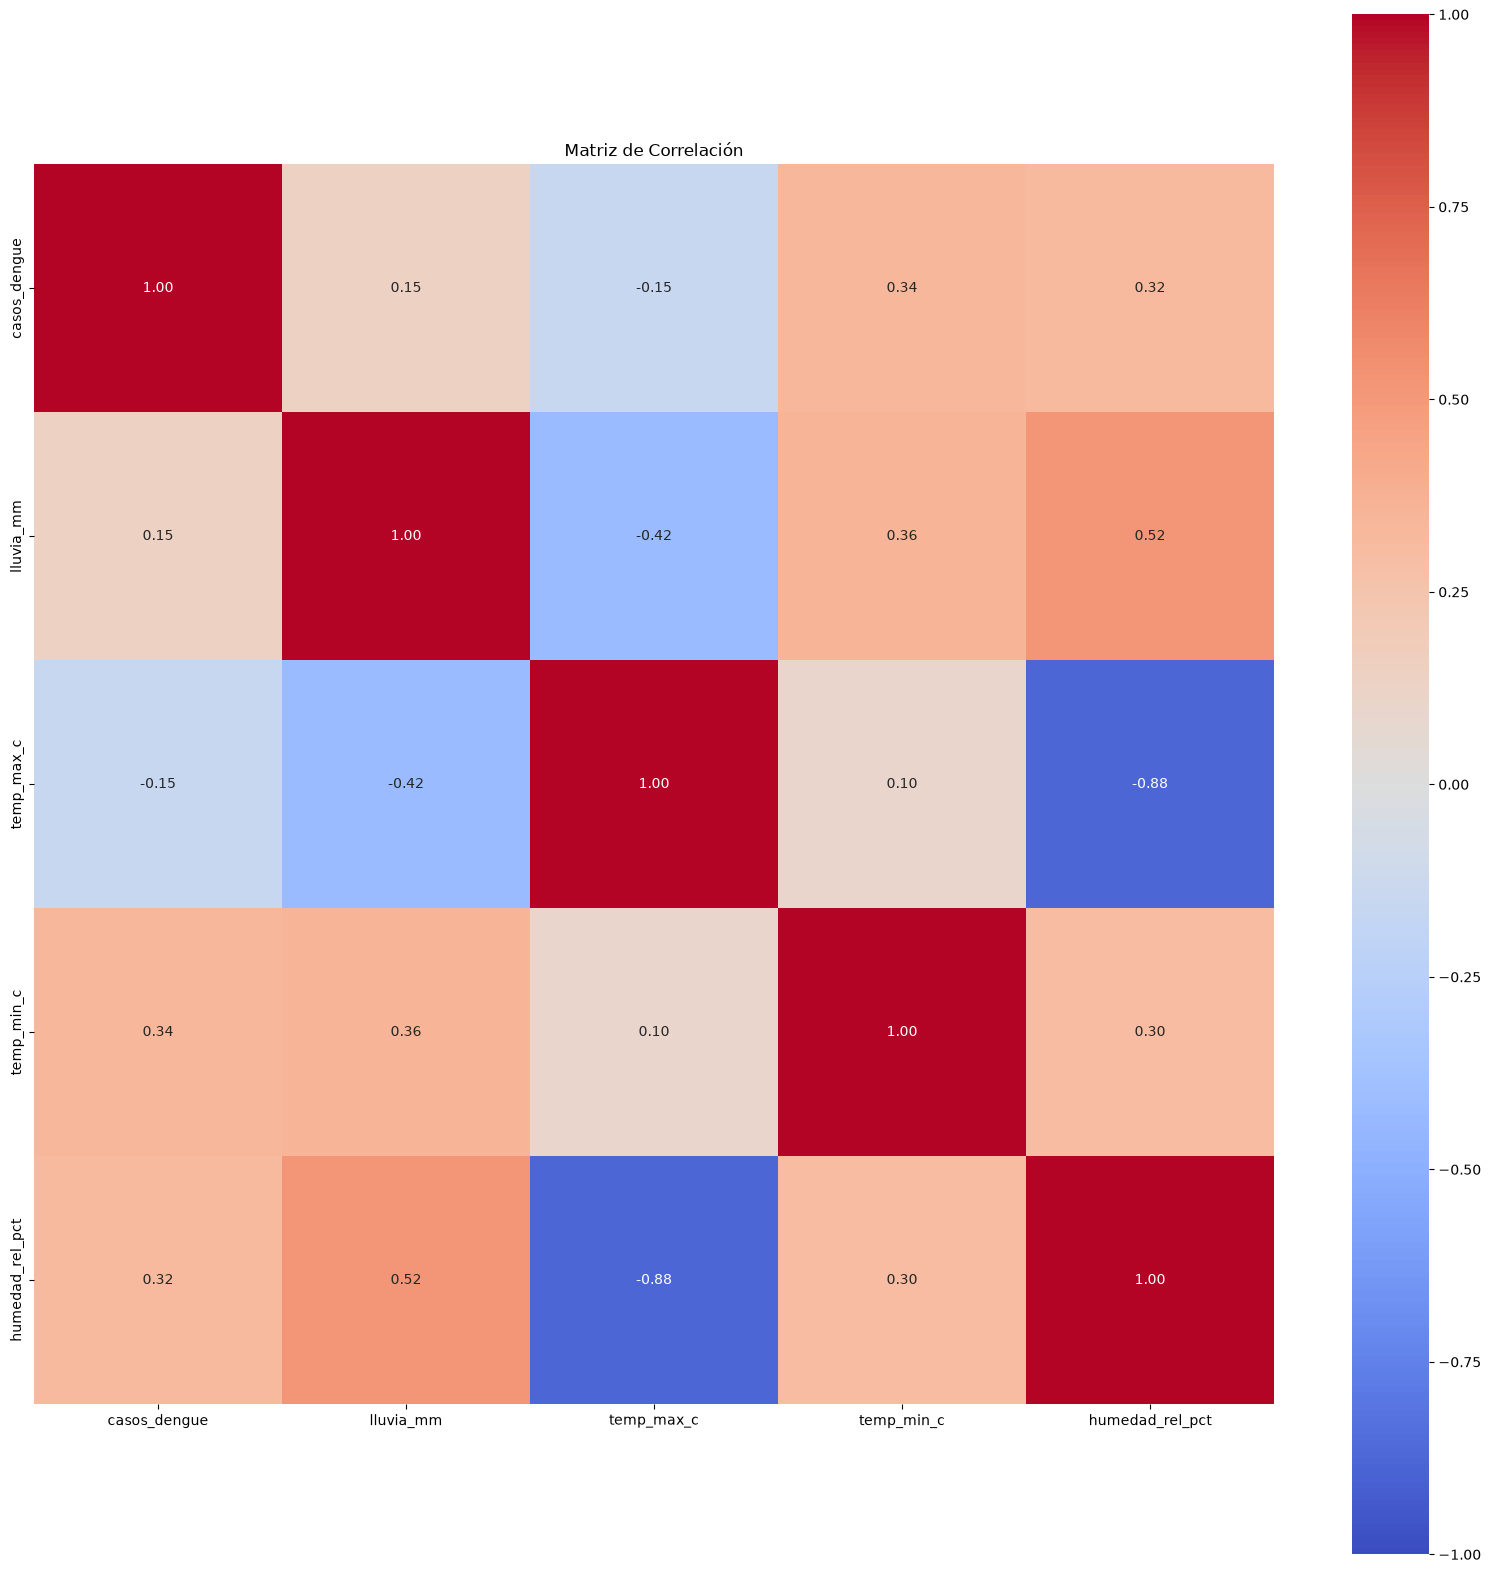

In [69]:
vectoria_dengue_nacional_real.graficos.corr(vectoria_dengue_nacional_real.data.drop(columns = ['provincia', 'region_climatica', 'poblacion']))

### Creacion de lags

In [70]:
vectoria_dengue_nacional_real.lags_x_col( columnas = ['lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct'])

6 lags de lluvia_mm creados
6 lags de temp_max_c creados
6 lags de temp_min_c creados
6 lags de humedad_rel_pct creados


In [71]:
vectoria_dengue_nacional_real.data

,provincia,region_climatica,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,lluvia_mm_lag6,lluvia_mm_lag5,...,temp_min_c_lag4,temp_min_c_lag3,temp_min_c_lag2,temp_min_c_lag1,humedad_rel_pct_lag6,humedad_rel_pct_lag5,humedad_rel_pct_lag4,humedad_rel_pct_lag3,humedad_rel_pct_lag2,humedad_rel_pct_lag1
fecha_inicio_semana,,,,,,,,,,,,,,,,,,,,,
2013-12-29,Costa Rica,Nacional,5170000,239,11.0,27.2,19.9,84.9,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-01-05,Costa Rica,Nacional,5170000,257,8.9,27.0,19.7,83.8,NaN,NaN,...,NaN,NaN,NaN,19.9,NaN,NaN,NaN,NaN,NaN,84.9
2014-01-12,Costa Rica,Nacional,5170000,184,4.5,27.1,19.5,81.7,NaN,NaN,...,NaN,NaN,19.9,19.7,NaN,NaN,NaN,NaN,84.9,83.8
2014-01-19,Costa Rica,Nacional,5170000,156,7.7,27.1,19.5,80.0,NaN,NaN,...,NaN,19.9,19.7,19.5,NaN,NaN,NaN,84.9,83.8,81.7
2014-01-26,Costa Rica,Nacional,5170000,189,4.7,27.2,18.7,78.0,NaN,NaN,...,19.9,19.7,19.5,19.5,NaN,NaN,84.9,83.8,81.7,80.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-24,Costa Rica,Nacional,5170000,402,64.9,26.7,21.2,91.4,87.4,66.2,...,21.8,21.6,21.2,20.7,91.5,90.3,90.5,93.9,94.9,90.7
2024-12-01,Costa Rica,Nacional,5170000,340,35.4,26.7,21.1,88.7,66.2,124.2,...,21.6,21.2,20.7,21.2,90.3,90.5,93.9,94.9,90.7,91.4
2024-12-08,Costa Rica,Nacional,5170000,312,14.5,27.6,21.1,85.7,124.2,236.4,...,21.2,20.7,21.2,21.1,90.5,93.9,94.9,90.7,91.4,88.7


###  Imputación Multivariable por Ecuaciones Encadenadas (MICE) para rellenar NAN

In [72]:
mice_col_names = list(vectoria_dengue_nacional_real.data.drop(columns = ['provincia', 'region_climatica', 'poblacion']).columns)

mice_col_names

['casos_dengue',
 'lluvia_mm',
 'temp_max_c',
 'temp_min_c',
 'humedad_rel_pct',
 'lluvia_mm_lag6',
 'lluvia_mm_lag5',
 'lluvia_mm_lag4',
 'lluvia_mm_lag3',
 'lluvia_mm_lag2',
 'lluvia_mm_lag1',
 'temp_max_c_lag6',
 'temp_max_c_lag5',
 'temp_max_c_lag4',
 'temp_max_c_lag3',
 'temp_max_c_lag2',
 'temp_max_c_lag1',
 'temp_min_c_lag6',
 'temp_min_c_lag5',
 'temp_min_c_lag4',
 'temp_min_c_lag3',
 'temp_min_c_lag2',
 'temp_min_c_lag1',
 'humedad_rel_pct_lag6',
 'humedad_rel_pct_lag5',
 'humedad_rel_pct_lag4',
 'humedad_rel_pct_lag3',
 'humedad_rel_pct_lag2',
 'humedad_rel_pct_lag1']

In [73]:
vectoria_dengue_nacional_real.data = vectoria_dengue_nacional_real.mice_imputation(
    iter = 50,
    col_imputar= mice_col_names
    ).imputed_data


In [74]:
vectoria_dengue_nacional_real.data

,provincia,region_climatica,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,lluvia_mm_lag6,lluvia_mm_lag5,...,temp_min_c_lag4,temp_min_c_lag3,temp_min_c_lag2,temp_min_c_lag1,humedad_rel_pct_lag6,humedad_rel_pct_lag5,humedad_rel_pct_lag4,humedad_rel_pct_lag3,humedad_rel_pct_lag2,humedad_rel_pct_lag1
fecha_inicio_semana,,,,,,,,,,,,,,,,,,,,,
2013-12-29,Costa Rica,Nacional,5170000,239,11.0,27.2,19.9,84.9,59.004620,53.352199,...,20.756873,20.688479,20.497006,20.346646,87.849200,87.463907,87.138853,87.124193,86.765423,86.497521
2014-01-05,Costa Rica,Nacional,5170000,257,8.9,27.0,19.7,83.8,56.940504,48.107708,...,20.537548,20.345077,20.199307,19.900000,89.100179,88.474653,87.879879,87.071430,86.430097,84.900000
2014-01-12,Costa Rica,Nacional,5170000,184,4.5,27.1,19.5,81.7,51.333229,43.579263,...,20.198229,20.067637,19.900000,19.700000,89.479515,88.693737,87.411558,86.302359,84.900000,83.800000
2014-01-19,Costa Rica,Nacional,5170000,156,7.7,27.1,19.5,80.0,46.743854,37.070619,...,19.996815,19.900000,19.700000,19.500000,89.624979,88.194547,86.662620,84.900000,83.800000,81.700000
2014-01-26,Costa Rica,Nacional,5170000,189,4.7,27.2,18.7,78.0,37.848450,27.329075,...,19.900000,19.700000,19.500000,19.500000,88.778761,87.137617,84.900000,83.800000,81.700000,80.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-11-24,Costa Rica,Nacional,5170000,402,64.9,26.7,21.2,91.4,87.400000,66.200000,...,21.800000,21.600000,21.200000,20.700000,91.500000,90.300000,90.500000,93.900000,94.900000,90.700000
2024-12-01,Costa Rica,Nacional,5170000,340,35.4,26.7,21.1,88.7,66.200000,124.200000,...,21.600000,21.200000,20.700000,21.200000,90.300000,90.500000,93.900000,94.900000,90.700000,91.400000
2024-12-08,Costa Rica,Nacional,5170000,312,14.5,27.6,21.1,85.7,124.200000,236.400000,...,21.200000,20.700000,21.200000,21.100000,90.500000,93.900000,94.900000,90.700000,91.400000,88.700000


## Analisis de vectoria_dengue_semanal

In [75]:
vectoria_dengue_semanal.data['fecha_inicio_semana'] = pd.to_datetime(vectoria_dengue_semanal.data['fecha_inicio_semana'])
vectoria_dengue_semanal.data = vectoria_dengue_semanal.data.set_index('fecha_inicio_semana')

vectoria_dengue_semanal.data.drop(columns = ['anio', 'tasa_100k', 'semana_epi'] , inplace = True)

vectoria_dengue_semanal.data.shape


/tmp/ipykernel_134566/432812475.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  vectoria_dengue_semanal.data.drop(columns = ['anio', 'tasa_100k', 'semana_epi'] , inplace = True)


(4382, 8)

In [76]:
vectoria_dengue_semanal.data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4382 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         4382 non-null   str    
 1   region_climatica  4382 non-null   str    
 2   poblacion         4382 non-null   int64  
 3   casos_dengue      4382 non-null   int64  
 4   lluvia_mm         4347 non-null   float64
 5   temp_max_c        4348 non-null   float64
 6   temp_min_c        4382 non-null   float64
 7   humedad_rel_pct   4353 non-null   float64
dtypes: float64(4), int64(2), str(2)
memory usage: 400.4 KB


In [77]:
vectoria_dengue_semanal.data.nunique()

provincia              7
region_climatica       4
poblacion              7
casos_dengue         186
lluvia_mm           1210
temp_max_c           174
temp_min_c           125
humedad_rel_pct      421
dtype: int64

In [78]:
vectoria_dengue_semanal.data.describe()

,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
count,4.382000e+03,4382.000000,4347.000000,4348.000000,4382.00000,4353.000000
mean,7.385714e+05,25.504336,38.802646,28.270262,19.41011,77.951321
std,4.350678e+05,32.393923,47.005264,3.671443,3.24215,9.701079
min,3.900000e+05,0.000000,0.000000,19.100000,12.50000,47.500000
25%,4.500000e+05,5.000000,5.400000,25.500000,17.00000,70.400000
50%,5.200000e+05,14.000000,22.000000,28.400000,18.80000,80.700000
75%,1.100000e+06,33.000000,55.900000,30.900000,22.60000,85.700000
max,1.660000e+06,341.000000,381.500000,37.100000,25.10000,96.100000


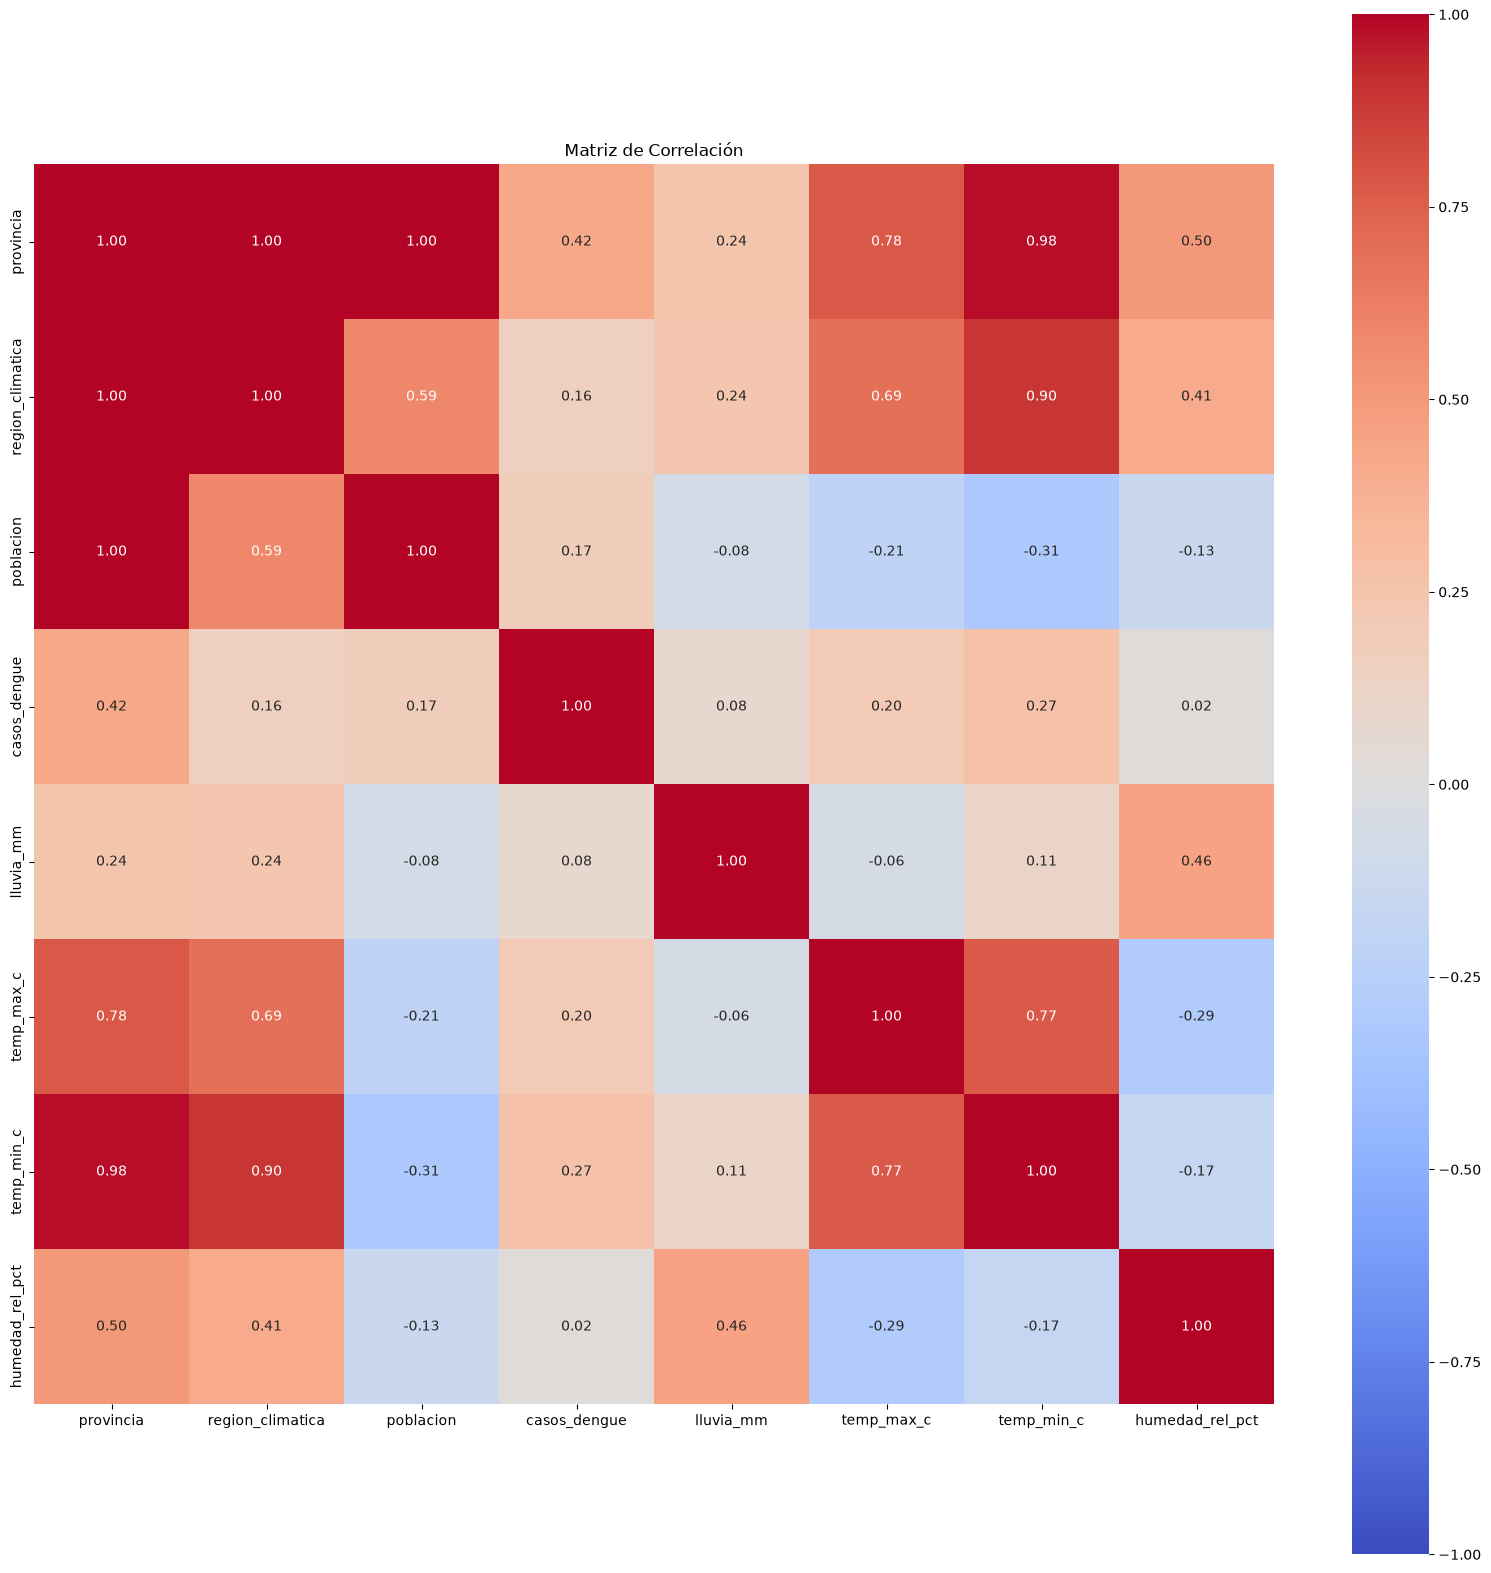

In [79]:
vectoria_dengue_semanal.graficos.corr(vectoria_dengue_semanal.data)

In [80]:
vectoria_dengue_semanal.data.iloc[0::626,:]

,provincia,region_climatica,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
fecha_inicio_semana,,,,,,,,
2014-01-05,Alajuela,Valle Central,1100000,27,0.0,27.1,18.9,58.1
2014-01-05,Cartago,Valle Central,550000,0,23.1,22.3,13.1,77.5
2014-01-05,Guanacaste,Pacífico Norte,390000,7,0.4,32.8,22.7,60.5
2014-01-05,Heredia,Valle Central,520000,3,0.9,25.6,16.2,70.0
2014-01-05,Limón,Caribe,450000,17,68.5,29.8,22.3,93.1
2014-01-05,Puntarenas,Pacífico Central/Sur,500000,35,0.1,31.2,25.1,68.0
2014-01-05,San José,Valle Central,1660000,21,0.0,26.1,17.4,67.9


In [81]:

vectoria_dengue_semanal.data.iloc[625::626,:]

,provincia,region_climatica,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
fecha_inicio_semana,,,,,,,,
2025-12-28,Alajuela,Valle Central,1100000,14,4.9,28.5,18.4,65.4
2025-12-28,Cartago,Valle Central,550000,3,41.5,21.5,13.0,86.9
2025-12-28,Guanacaste,Pacífico Norte,390000,13,2.3,33.0,22.0,57.0
2025-12-28,Heredia,Valle Central,520000,5,18.5,25.6,16.6,71.9
2025-12-28,Limón,Caribe,450000,33,127.2,29.0,22.7,90.5
2025-12-28,Puntarenas,Pacífico Central/Sur,500000,27,5.3,32.0,23.2,68.1
2025-12-28,San José,Valle Central,1660000,5,2.9,26.0,17.4,69.1


In [82]:
vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Cartago'].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         618 non-null    float64
 5   temp_max_c        616 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   623 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 56.4 KB


In [83]:
vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Alajuela'].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         621 non-null    float64
 5   temp_max_c        620 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   624 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 57.0 KB


In [84]:
vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Guanacaste'].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         621 non-null    float64
 5   temp_max_c        621 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   622 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 59.5 KB


In [85]:
vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Heredia'].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         619 non-null    float64
 5   temp_max_c        623 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   623 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 56.4 KB


In [86]:
vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Limón'].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         621 non-null    float64
 5   temp_max_c        622 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   618 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 51.5 KB


In [87]:
vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Puntarenas'].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         621 non-null    float64
 5   temp_max_c        624 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   620 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 63.1 KB


In [88]:
vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'San José'].info()

<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        622 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   623 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 57.6 KB


##  MICE por provincia

In [89]:
cartago_data = vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Cartago']
alajuela_data = vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Alajuela']
guanacaste_data  = vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Guanacaste']
heredia_data = vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Heredia']
limon_data  = vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Limón']
san_jose_data  = vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'San José']
puntarenas_data = vectoria_dengue_semanal.data[ vectoria_dengue_semanal.data['provincia'] == 'Puntarenas']

In [90]:
cartago_data

,provincia,region_climatica,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
fecha_inicio_semana,,,,,,,,
2014-01-05,Cartago,Valle Central,550000,0,23.1,22.3,13.1,77.5
2014-01-12,Cartago,Valle Central,550000,0,8.3,23.2,14.9,79.9
2014-01-19,Cartago,Valle Central,550000,2,7.4,22.1,12.9,80.7
2014-01-26,Cartago,Valle Central,550000,1,41.2,23.0,14.8,82.1
2014-02-02,Cartago,Valle Central,550000,3,0.3,22.4,13.7,82.2
...,...,...,...,...,...,...,...,...
2025-11-30,Cartago,Valle Central,550000,0,47.0,22.0,14.2,85.6
2025-12-07,Cartago,Valle Central,550000,3,15.3,22.4,13.8,81.9
2025-12-14,Cartago,Valle Central,550000,0,9.3,22.0,12.8,80.9


In [91]:
cartago_data = vectoria_dengue_semanal.mice_imputation(data = cartago_data, col_imputar= ['casos_dengue', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).imputed_data
alajuela_data = vectoria_dengue_semanal.mice_imputation(data = alajuela_data,col_imputar= ['casos_dengue', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).imputed_data
guanacaste_data = vectoria_dengue_semanal.mice_imputation(data = guanacaste_data,col_imputar= ['casos_dengue', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).imputed_data
heredia_data = vectoria_dengue_semanal.mice_imputation(data = heredia_data,col_imputar= ['casos_dengue', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).imputed_data
limon_data = vectoria_dengue_semanal.mice_imputation(data = limon_data,col_imputar= ['casos_dengue', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).imputed_data
san_jose_data = vectoria_dengue_semanal.mice_imputation(data = san_jose_data,col_imputar= ['casos_dengue', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).imputed_data
puntarenas_data = vectoria_dengue_semanal.mice_imputation(data = puntarenas_data,col_imputar= ['casos_dengue', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).imputed_data



In [92]:
cartago_data.info()



<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        626 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   626 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 56.4 KB


In [93]:
alajuela_data.info()


<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        626 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   626 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 57.0 KB


In [94]:
guanacaste_data.info()



<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        626 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   626 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 59.5 KB


In [95]:
heredia_data.info()



<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        626 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   626 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 56.4 KB


In [96]:
heredia_data.info()



<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        626 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   626 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 56.4 KB


In [97]:
limon_data.info()



<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        626 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   626 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 51.5 KB


In [98]:
san_jose_data.info()



<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        626 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   626 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 57.6 KB


In [99]:
puntarenas_data.info()


<class 'pandas.DataFrame'>
DatetimeIndex: 626 entries, 2014-01-05 to 2025-12-28
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   provincia         626 non-null    str    
 1   region_climatica  626 non-null    str    
 2   poblacion         626 non-null    int64  
 3   casos_dengue      626 non-null    int64  
 4   lluvia_mm         626 non-null    float64
 5   temp_max_c        626 non-null    float64
 6   temp_min_c        626 non-null    float64
 7   humedad_rel_pct   626 non-null    float64
dtypes: float64(4), int64(2), str(2)
memory usage: 63.1 KB


### Reapaso por provincia

#### Temperatura

<Axes: xlabel='fecha_inicio_semana'>

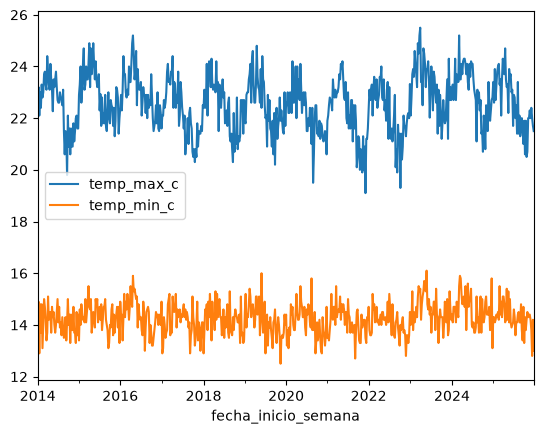

In [100]:
cartago_data.drop(columns= ['poblacion', 'lluvia_mm', 'casos_dengue', 'humedad_rel_pct']).plot()

<Axes: xlabel='fecha_inicio_semana'>

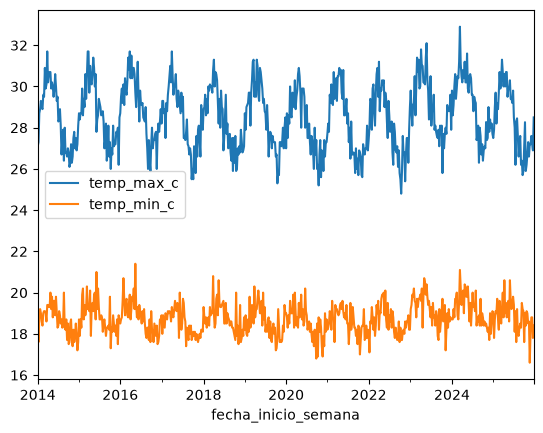

In [101]:
alajuela_data.drop(columns= ['poblacion', 'lluvia_mm', 'casos_dengue', 'humedad_rel_pct']).plot()

<Axes: xlabel='fecha_inicio_semana'>

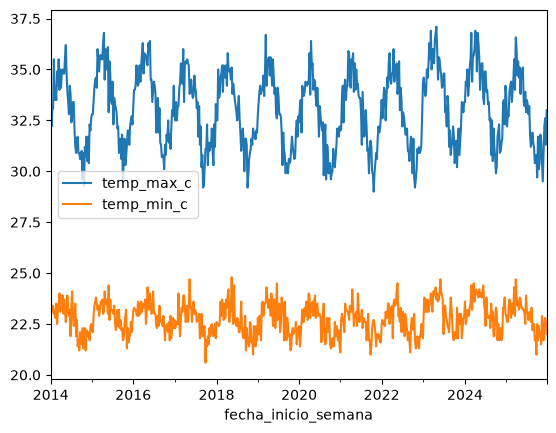

In [102]:
guanacaste_data.drop(columns= ['poblacion', 'lluvia_mm', 'casos_dengue', 'humedad_rel_pct']).plot()

<Axes: xlabel='fecha_inicio_semana'>

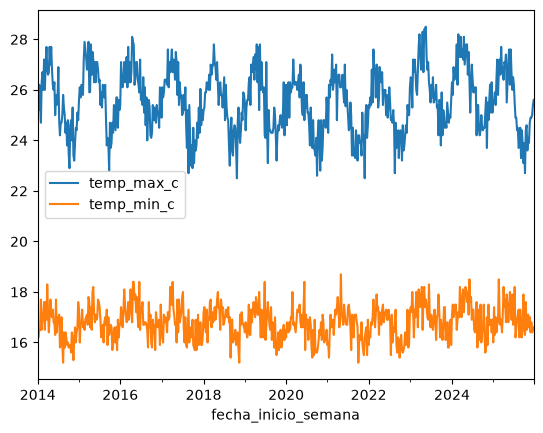

In [103]:
heredia_data.drop(columns= ['poblacion', 'lluvia_mm', 'casos_dengue', 'humedad_rel_pct']).plot()

<Axes: xlabel='fecha_inicio_semana'>

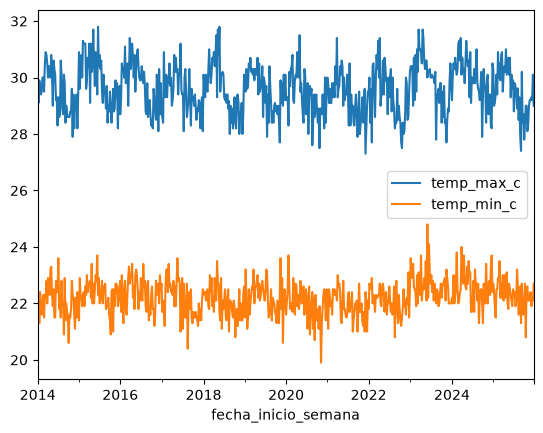

In [104]:
limon_data.drop(columns= ['poblacion', 'lluvia_mm', 'casos_dengue', 'humedad_rel_pct']).plot()

<Axes: xlabel='fecha_inicio_semana'>

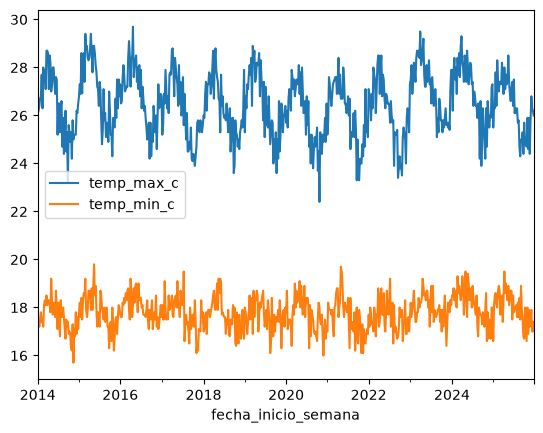

In [105]:
san_jose_data.drop(columns= ['poblacion', 'lluvia_mm', 'casos_dengue', 'humedad_rel_pct']).plot()

<Axes: xlabel='fecha_inicio_semana'>

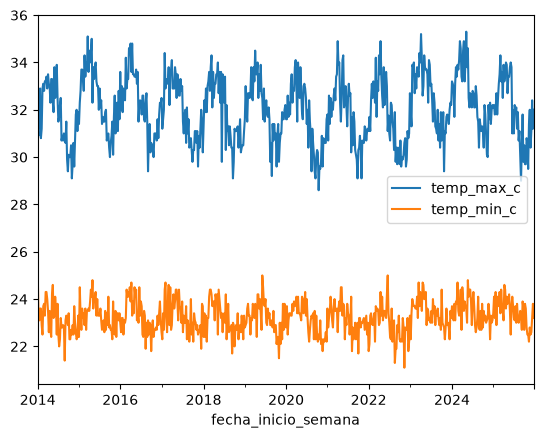

In [106]:
puntarenas_data.drop(columns= ['poblacion', 'lluvia_mm', 'casos_dengue', 'humedad_rel_pct']).plot()

#### Milimetros de lluvia

<Axes: xlabel='fecha_inicio_semana'>

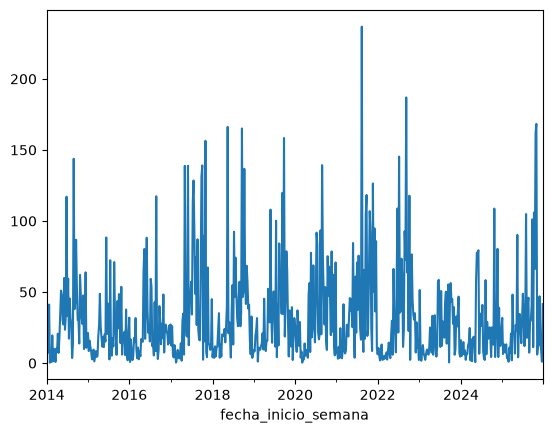

In [107]:
cartago_data['lluvia_mm'].plot()

<Axes: xlabel='fecha_inicio_semana'>

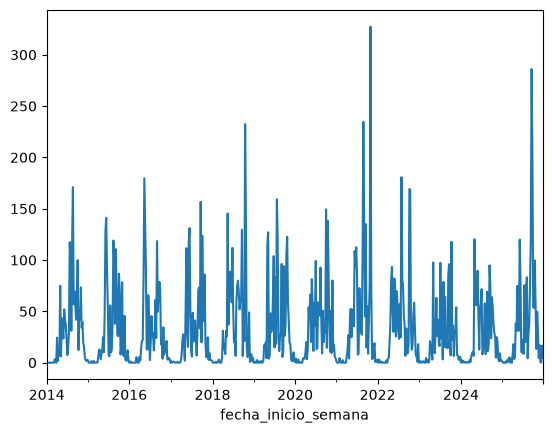

In [108]:
alajuela_data['lluvia_mm'].plot()

<Axes: xlabel='fecha_inicio_semana'>

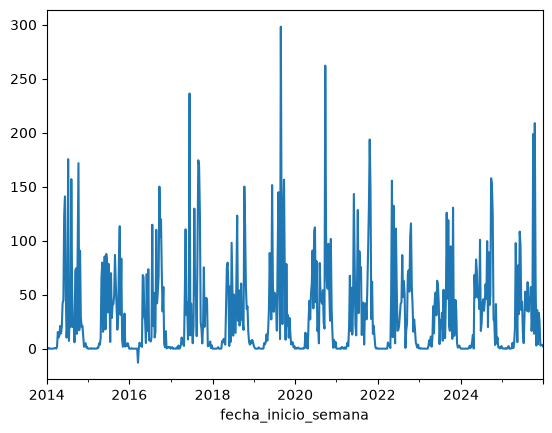

In [109]:
guanacaste_data['lluvia_mm'].plot()

<Axes: xlabel='fecha_inicio_semana'>

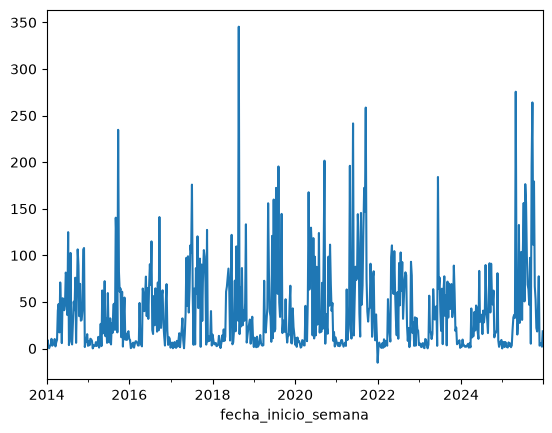

In [110]:
heredia_data['lluvia_mm'].plot()

<Axes: xlabel='fecha_inicio_semana'>

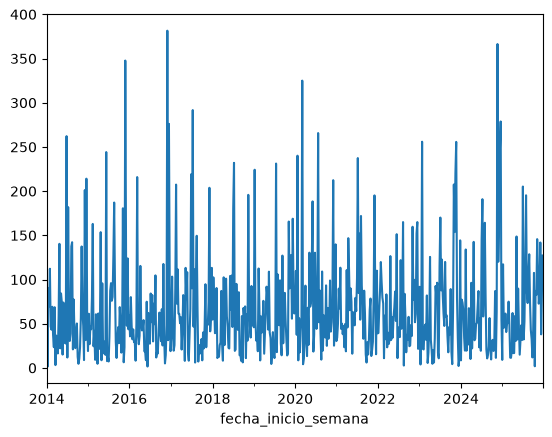

In [111]:
limon_data['lluvia_mm'].plot()

<Axes: xlabel='fecha_inicio_semana'>

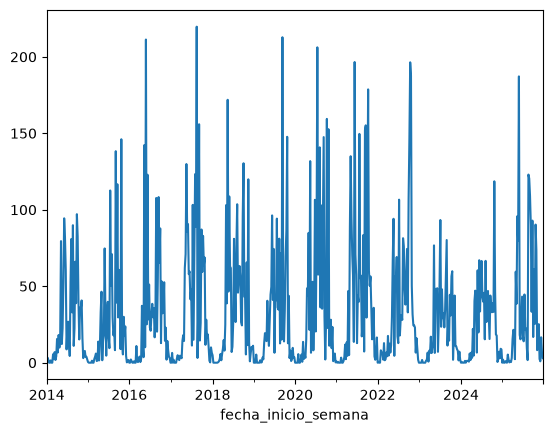

In [112]:
san_jose_data['lluvia_mm'].plot()

<Axes: xlabel='fecha_inicio_semana'>

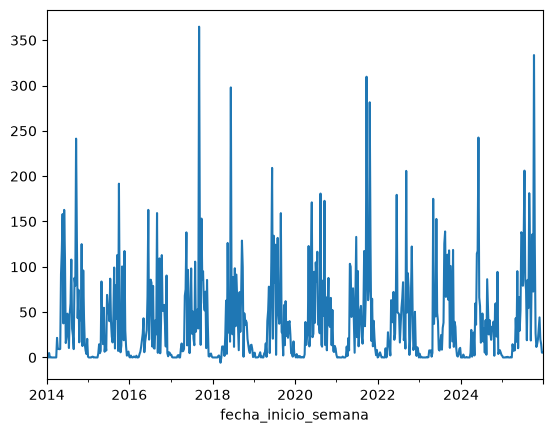

In [113]:
puntarenas_data['lluvia_mm'].plot()

#### Humedad

<Axes: xlabel='fecha_inicio_semana'>

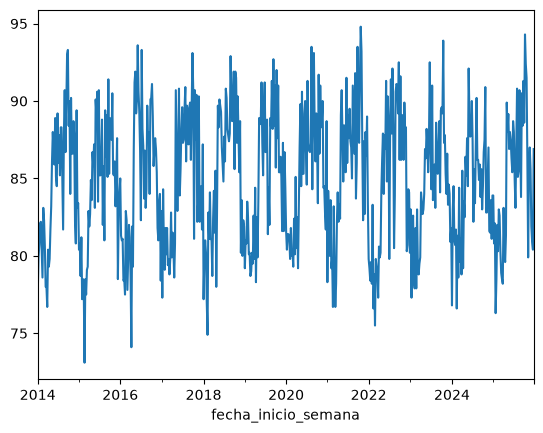

In [114]:
cartago_data['humedad_rel_pct'].plot()

<Axes: xlabel='fecha_inicio_semana'>

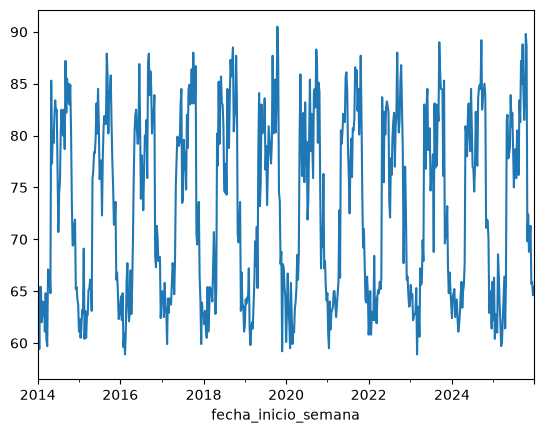

In [115]:
alajuela_data['humedad_rel_pct'].plot()

<Axes: xlabel='fecha_inicio_semana'>

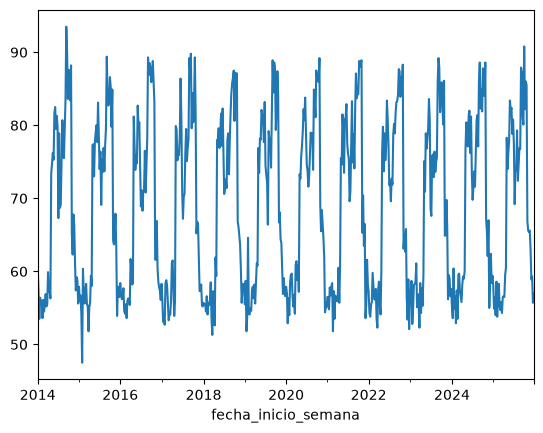

In [116]:
guanacaste_data['humedad_rel_pct'].plot()

<Axes: xlabel='fecha_inicio_semana'>

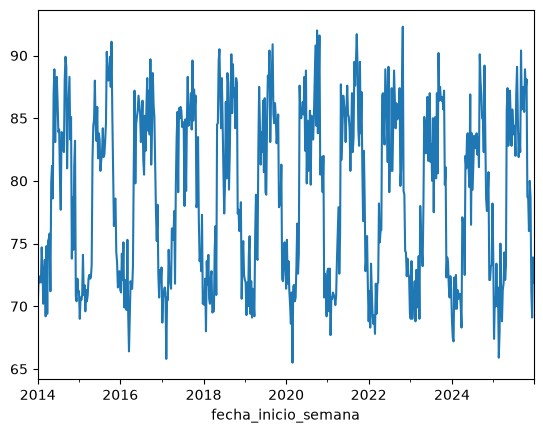

In [117]:
heredia_data['humedad_rel_pct'].plot()

<Axes: xlabel='fecha_inicio_semana'>

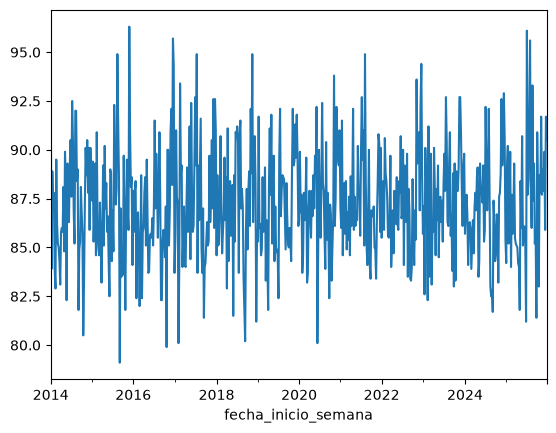

In [118]:
limon_data['humedad_rel_pct'].plot()

<Axes: xlabel='fecha_inicio_semana'>

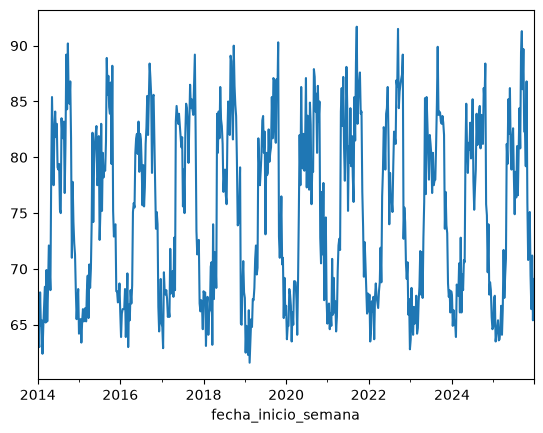

In [119]:
san_jose_data['humedad_rel_pct'].plot()

<Axes: xlabel='fecha_inicio_semana'>

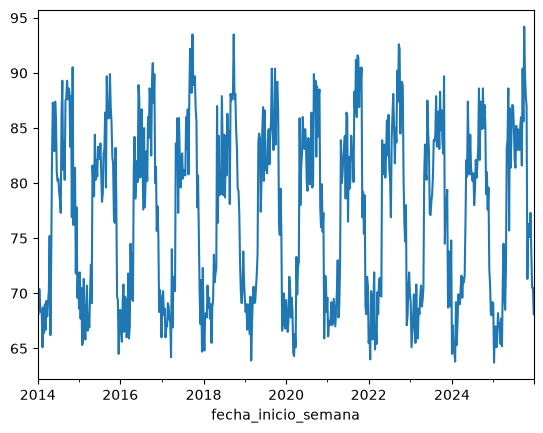

In [120]:
puntarenas_data['humedad_rel_pct'].plot()

### Creacion de lags

In [121]:
print('Cartago:')
cartago_data = vectoria_dengue_semanal.lags_x_col(data = cartago_data, columnas = ['lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).data
print('\n')
print('Alajuela:')
alajuela_data = vectoria_dengue_semanal.lags_x_col(data = alajuela_data, columnas = ['lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).data
print('\n')
print('Guanacaste:')
guanacaste_data = vectoria_dengue_semanal.lags_x_col(data = guanacaste_data, columnas = ['lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).data
print('\n')
print('Heredia:')
heredia_data = vectoria_dengue_semanal.lags_x_col(data = heredia_data, columnas = ['lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).data
print('\n')
print('Limon:')
limon_data = vectoria_dengue_semanal.lags_x_col(data = limon_data, columnas = ['lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).data
print('\n')
print('San Jose:')
san_jose_data = vectoria_dengue_semanal.lags_x_col(data = san_jose_data, columnas = ['lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).data
print('\n')
print('Puntarenas:')
puntarenas_data = vectoria_dengue_semanal.lags_x_col(data = puntarenas_data, columnas = ['lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']).data

Cartago:
6 lags de lluvia_mm creados
6 lags de temp_max_c creados
6 lags de temp_min_c creados
6 lags de humedad_rel_pct creados


Alajuela:
6 lags de lluvia_mm creados
6 lags de temp_max_c creados
6 lags de temp_min_c creados
6 lags de humedad_rel_pct creados


Guanacaste:
6 lags de lluvia_mm creados
6 lags de temp_max_c creados
6 lags de temp_min_c creados
6 lags de humedad_rel_pct creados


Heredia:
6 lags de lluvia_mm creados
6 lags de temp_max_c creados
6 lags de temp_min_c creados
6 lags de humedad_rel_pct creados


Limon:
6 lags de lluvia_mm creados
6 lags de temp_max_c creados
6 lags de temp_min_c creados
6 lags de humedad_rel_pct creados


San Jose:
6 lags de lluvia_mm creados
6 lags de temp_max_c creados
6 lags de temp_min_c creados
6 lags de humedad_rel_pct creados


Puntarenas:
6 lags de lluvia_mm creados
6 lags de temp_max_c creados
6 lags de temp_min_c creados
6 lags de humedad_rel_pct creados


In [122]:
cartago_data

,provincia,region_climatica,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,lluvia_mm_lag6,lluvia_mm_lag5,...,temp_min_c_lag4,temp_min_c_lag3,temp_min_c_lag2,temp_min_c_lag1,humedad_rel_pct_lag6,humedad_rel_pct_lag5,humedad_rel_pct_lag4,humedad_rel_pct_lag3,humedad_rel_pct_lag2,humedad_rel_pct_lag1
fecha_inicio_semana,,,,,,,,,,,,,,,,,,,,,
2014-01-05,Cartago,Valle Central,550000,0,23.1,22.3,13.1,77.5,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-01-12,Cartago,Valle Central,550000,0,8.3,23.2,14.9,79.9,NaN,NaN,...,NaN,NaN,NaN,13.1,NaN,NaN,NaN,NaN,NaN,77.5
2014-01-19,Cartago,Valle Central,550000,2,7.4,22.1,12.9,80.7,NaN,NaN,...,NaN,NaN,13.1,14.9,NaN,NaN,NaN,NaN,77.5,79.9
2014-01-26,Cartago,Valle Central,550000,1,41.2,23.0,14.8,82.1,NaN,NaN,...,NaN,13.1,14.9,12.9,NaN,NaN,NaN,77.5,79.9,80.7
2014-02-02,Cartago,Valle Central,550000,3,0.3,22.4,13.7,82.2,NaN,NaN,...,13.1,14.9,12.9,14.8,NaN,NaN,77.5,79.9,80.7,82.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-30,Cartago,Valle Central,550000,0,47.0,22.0,14.2,85.6,66.2,161.7,...,14.5,14.3,14.4,14.4,92.4,91.5,86.2,79.9,86.0,87.0
2025-12-07,Cartago,Valle Central,550000,3,15.3,22.4,13.8,81.9,161.7,168.3,...,14.3,14.4,14.4,14.2,91.5,86.2,79.9,86.0,87.0,85.6
2025-12-14,Cartago,Valle Central,550000,0,9.3,22.0,12.8,80.9,168.3,6.0,...,14.4,14.4,14.2,13.8,86.2,79.9,86.0,87.0,85.6,81.9


#### MICE para rellenar NAN

Se implemetan los mismos nombres usados en la imputacionde datos nacionales al momentop de crear los lags

In [123]:
mice_col_names

['casos_dengue',
 'lluvia_mm',
 'temp_max_c',
 'temp_min_c',
 'humedad_rel_pct',
 'lluvia_mm_lag6',
 'lluvia_mm_lag5',
 'lluvia_mm_lag4',
 'lluvia_mm_lag3',
 'lluvia_mm_lag2',
 'lluvia_mm_lag1',
 'temp_max_c_lag6',
 'temp_max_c_lag5',
 'temp_max_c_lag4',
 'temp_max_c_lag3',
 'temp_max_c_lag2',
 'temp_max_c_lag1',
 'temp_min_c_lag6',
 'temp_min_c_lag5',
 'temp_min_c_lag4',
 'temp_min_c_lag3',
 'temp_min_c_lag2',
 'temp_min_c_lag1',
 'humedad_rel_pct_lag6',
 'humedad_rel_pct_lag5',
 'humedad_rel_pct_lag4',
 'humedad_rel_pct_lag3',
 'humedad_rel_pct_lag2',
 'humedad_rel_pct_lag1']

In [124]:
cartago_data = vectoria_dengue_semanal.mice_imputation(iter = 50, data = cartago_data, col_imputar= mice_col_names).imputed_data
alajuela_data = vectoria_dengue_semanal.mice_imputation(iter = 50, data = alajuela_data,col_imputar= mice_col_names).imputed_data
guanacaste_data = vectoria_dengue_semanal.mice_imputation(iter = 50, data = guanacaste_data,col_imputar= mice_col_names).imputed_data
heredia_data = vectoria_dengue_semanal.mice_imputation(iter = 50, data = heredia_data,col_imputar= mice_col_names).imputed_data
limon_data = vectoria_dengue_semanal.mice_imputation(iter = 50, data = limon_data,col_imputar= mice_col_names).imputed_data
san_jose_data = vectoria_dengue_semanal.mice_imputation(iter = 50, data = san_jose_data,col_imputar= mice_col_names).imputed_data
puntarenas_data = vectoria_dengue_semanal.mice_imputation(iter = 50, data = puntarenas_data,col_imputar= mice_col_names).imputed_data

In [125]:
cartago_data

,provincia,region_climatica,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,lluvia_mm_lag6,lluvia_mm_lag5,...,temp_min_c_lag4,temp_min_c_lag3,temp_min_c_lag2,temp_min_c_lag1,humedad_rel_pct_lag6,humedad_rel_pct_lag5,humedad_rel_pct_lag4,humedad_rel_pct_lag3,humedad_rel_pct_lag2,humedad_rel_pct_lag1
fecha_inicio_semana,,,,,,,,,,,,,,,,,,,,,
2014-01-05,Cartago,Valle Central,550000,0,23.1,22.3,13.1,77.5,32.943150,29.376078,...,13.882245,14.037054,14.109713,14.171414,83.822460,83.217562,82.539912,82.201380,81.414896,80.772902
2014-01-12,Cartago,Valle Central,550000,0,8.3,23.2,14.9,79.9,24.202989,18.103188,...,14.072128,14.153809,14.245920,13.100000,82.440207,81.984653,81.585320,80.795029,80.395697,77.500000
2014-01-19,Cartago,Valle Central,550000,2,7.4,22.1,12.9,80.7,25.776759,18.942768,...,14.035045,14.141254,13.100000,14.900000,83.217152,82.464717,81.669524,81.275209,77.500000,79.900000
2014-01-26,Cartago,Valle Central,550000,1,41.2,23.0,14.8,82.1,17.642516,19.564490,...,14.194230,13.100000,14.900000,12.900000,82.086136,81.458542,81.157730,77.500000,79.900000,80.700000
2014-02-02,Cartago,Valle Central,550000,3,0.3,22.4,13.7,82.2,21.252744,16.979066,...,13.100000,14.900000,12.900000,14.800000,81.958630,81.433281,77.500000,79.900000,80.700000,82.100000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-30,Cartago,Valle Central,550000,0,47.0,22.0,14.2,85.6,66.200000,161.700000,...,14.500000,14.300000,14.400000,14.400000,92.400000,91.500000,86.200000,79.900000,86.000000,87.000000
2025-12-07,Cartago,Valle Central,550000,3,15.3,22.4,13.8,81.9,161.700000,168.300000,...,14.300000,14.400000,14.400000,14.200000,91.500000,86.200000,79.900000,86.000000,87.000000,85.600000
2025-12-14,Cartago,Valle Central,550000,0,9.3,22.0,12.8,80.9,168.300000,6.000000,...,14.400000,14.400000,14.200000,13.800000,86.200000,79.900000,86.000000,87.000000,85.600000,81.900000


### Union de los datos por provincia en un solo dataset nuevo

In [126]:
dfs_provincia = {
    "Cartago": cartago_data,
    "Alajuela": alajuela_data,
    "Guanacaste": guanacaste_data,
    "Heredia": heredia_data,
    "Limón": limon_data,
    "San José": san_jose_data,
    "Puntarenas": puntarenas_data,
}

datos_imputados = pd.concat(
    [
        df.assign(provincia=provincia)
        for provincia, df in dfs_provincia.items()
    ],
    axis=0,
    ignore_index=False,
)

vectoria_dengue_semanal.data = datos_imputados

In [127]:
vectoria_dengue_semanal.data

,provincia,region_climatica,poblacion,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,lluvia_mm_lag6,lluvia_mm_lag5,...,temp_min_c_lag4,temp_min_c_lag3,temp_min_c_lag2,temp_min_c_lag1,humedad_rel_pct_lag6,humedad_rel_pct_lag5,humedad_rel_pct_lag4,humedad_rel_pct_lag3,humedad_rel_pct_lag2,humedad_rel_pct_lag1
fecha_inicio_semana,,,,,,,,,,,,,,,,,,,,,
2014-01-05,Cartago,Valle Central,550000,0,23.1,22.3,13.1,77.5,32.943150,29.376078,...,13.882245,14.037054,14.109713,14.171414,83.822460,83.217562,82.539912,82.201380,81.414896,80.772902
2014-01-12,Cartago,Valle Central,550000,0,8.3,23.2,14.9,79.9,24.202989,18.103188,...,14.072128,14.153809,14.245920,13.100000,82.440207,81.984653,81.585320,80.795029,80.395697,77.500000
2014-01-19,Cartago,Valle Central,550000,2,7.4,22.1,12.9,80.7,25.776759,18.942768,...,14.035045,14.141254,13.100000,14.900000,83.217152,82.464717,81.669524,81.275209,77.500000,79.900000
2014-01-26,Cartago,Valle Central,550000,1,41.2,23.0,14.8,82.1,17.642516,19.564490,...,14.194230,13.100000,14.900000,12.900000,82.086136,81.458542,81.157730,77.500000,79.900000,80.700000
2014-02-02,Cartago,Valle Central,550000,3,0.3,22.4,13.7,82.2,21.252744,16.979066,...,13.100000,14.900000,12.900000,14.800000,81.958630,81.433281,77.500000,79.900000,80.700000,82.100000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-30,Puntarenas,Pacífico Central/Sur,500000,12,44.2,30.4,22.5,77.3,126.000000,26.700000,...,22.500000,22.500000,22.200000,22.800000,87.900000,87.000000,71.300000,75.800000,76.300000,75.100000
2025-12-07,Puntarenas,Pacífico Central/Sur,500000,11,19.8,31.1,22.6,73.5,26.700000,11.600000,...,22.500000,22.200000,22.800000,22.500000,87.000000,71.300000,75.800000,76.300000,75.100000,77.300000
2025-12-14,Puntarenas,Pacífico Central/Sur,500000,18,14.8,32.4,23.2,70.5,11.600000,14.800000,...,22.200000,22.800000,22.500000,22.600000,71.300000,75.800000,76.300000,75.100000,77.300000,73.500000


In [128]:
vectoria_dengue_semanal.data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4382 entries, 2014-01-05 to 2025-12-28
Data columns (total 32 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   provincia             4382 non-null   str    
 1   region_climatica      4382 non-null   str    
 2   poblacion             4382 non-null   int64  
 3   casos_dengue          4382 non-null   int64  
 4   lluvia_mm             4382 non-null   float64
 5   temp_max_c            4382 non-null   float64
 6   temp_min_c            4382 non-null   float64
 7   humedad_rel_pct       4382 non-null   float64
 8   lluvia_mm_lag6        4382 non-null   float64
 9   lluvia_mm_lag5        4382 non-null   float64
 10  lluvia_mm_lag4        4382 non-null   float64
 11  lluvia_mm_lag3        4382 non-null   float64
 12  lluvia_mm_lag2        4382 non-null   float64
 13  lluvia_mm_lag1        4382 non-null   float64
 14  temp_max_c_lag6       4382 non-null   float64
 15  temp_max_c_lag

## Guardado de la data tratada

Se guarda los archivos en formato .parquet para conservar los tipos de datos en las columnas

In [130]:
vectoria_acciones.save_data('../data/proceced/archivos_parquet/vectoria_acciones.parquet')

vectoria_dengue_nacional_real.save_data('../data/proceced/archivos_parquet/vectoria_dengue_nacional_real.parquet')

vectoria_dengue_semanal.save_data('../data/proceced/archivos_parquet/vectoria_dengue_semanal.parquet')
